# EMiF Project 2 — Has the Structure of Risk Changed Since COVID-19?

**Group Members:** Matteo Piras, Marco D’Amico, Roberto Berardi 

## Research Question
Can we say that, since COVID-19, the structure of risk in financial markets has fundamentally changed? Specifically: did volatility become more persistent, did the stock–bond diversification relationship break down, and did tail risk increase?

## Data Rule
This notebook uses **only** the file `Data.xlsx` provided for the project. No external data sources, APIs, or downloads are used at any point.

## Implementation Note
The raw dataset contains equity, credit, commodity and yield series. For the **modelling chain**
(GARCH, DCC, H_t and ERC), raw yield changes are converted into **duration-based bond-return proxies**:

- `us10y_bond_proxy = -8.5 × ΔUS10Y / 100`
- `de10y_bond_proxy = -9.0 × ΔDE10Y / 100`

The original `returns_daily` dataset is kept unchanged for descriptive work. A separate
`returns_model` dataset is used whenever return-compatible inputs are required by the
multivariate volatility and portfolio steps.

For Sharpe-ratio calculations, the notebook uses an **internal risk-free proxy** constructed
from the US 10-year yield level already present in `Data.xlsx`. This is not a textbook
3-month T-bill rate; it is a transparent in-sample approximation used because the project
forbids external data.

## Notebook Structure
- **Steps 1–6** — Setup, data loading, return computation, duration proxies, sample splits
- **Steps 7–10** — Descriptive statistics, normality tests, ARCH diagnostics, volatility clustering
- **Steps 11–14** — GARCH order selection, full-sample estimation, pre/post comparison, standardised residuals
- **Steps 15–18** — Rolling correlations, DCC filter, DCC charts, pre/post formal tests
- **Steps 19–22** — Structural breaks, Markov-switching, extended history, regime zoom
- **Steps 23–26** — 60/40 portfolio, ERC portfolio, final summary, EWMA robustness check

## 1. Setup and Data Loading

All libraries are imported, output directories configured and the raw Excel file loaded. Figures and tables are saved to `Figures/` and `Tables/` respectively. Sheet names are printed to verify the file structure before any column selection.

In [1]:
import os
from pathlib import Path
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from scipy import stats
from scipy.stats import jarque_bera, skew, kurtosis, ttest_ind
from scipy import optimize as opt
from scipy.optimize import minimize
from scipy.special import gammaln

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_arch, acorr_ljungbox
from statsmodels.tsa.regime_switching.markov_regression import MarkovRegression
from statsmodels.tsa.stattools import adfuller

warnings.filterwarnings("ignore")

FIG_DIR = Path("Figures")
TAB_DIR = Path("Tables")
FIG_DIR.mkdir(exist_ok=True)
TAB_DIR.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi"      : 150,
    "axes.spines.top" : False,
    "axes.spines.right": False,
    "axes.grid"       : True,
    "grid.alpha"      : 0.3,
    "font.size"       : 10,
})

DATA_PATH = Path("Data.xlsx")
xls       = pd.ExcelFile(DATA_PATH)

print("Libraries loaded")
print(f"Output folders ready: {FIG_DIR}/  |  {TAB_DIR}/")
print("Sheet names:", xls.sheet_names)

Libraries loaded
Output folders ready: Figures/  |  Tables/
Sheet names: ['Feuil1']


## 2. Raw Data Inspection

The first sheet of the Excel file is loaded and the index is parsed as dates. The raw column names, shape, date range, data types and missing value counts are printed before any renaming or filtering is applied.

In [2]:
df_raw = pd.read_excel(DATA_PATH, sheet_name=xls.sheet_names[0], index_col=0)

df_raw.index = pd.to_datetime(df_raw.index, dayfirst=True, errors="coerce")
df_raw       = df_raw.sort_index()
df_raw       = df_raw[df_raw.index.notna()]

print(df_raw.head(10).to_string())

print("\nColumn names:")
for i, col in enumerate(df_raw.columns):
    print(f"  [{i:>2}]  {repr(col)}")

print(f"\nShape: {df_raw.shape[0]:,} rows  x  {df_raw.shape[1]} columns")
print(f"Date range: {df_raw.index[0].date()} to {df_raw.index[-1].date()}")

print("\nData types:")
print(df_raw.dtypes.to_string())

print("\nMissing values:")
missing     = df_raw.isna().sum().rename("missing_count")
missing_pct = (df_raw.isna().mean() * 100).rename("missing_pct").round(2)
missing_summary = pd.concat([missing, missing_pct], axis=1)
missing_summary["first_valid"] = [
    df_raw[col].first_valid_index().date() if df_raw[col].notna().any() else None
    for col in df_raw.columns
]
print(missing_summary.to_string())

            S&P500  Eurostoxx 50  Hang Seng  MSCI EM     SMI  US T 10-year Yield  German Gov 10-year yield  Oil futures    Gold  EURUSD  USDJPY  US IG Bonds  US HY Bonds  USDCHF
1989-12-31     NaN           NaN        NaN      NaN     NaN                 NaN                       NaN          NaN     NaN     NaN     NaN      447.981      182.305     NaN
1990-01-01     NaN     1098.4900        NaN   214.69     NaN                 NaN                       NaN          NaN     NaN     NaN  143.80          NaN          NaN  1.5410
1990-01-02  359.69     1101.3400  2838.0701   217.30     NaN               7.930                     7.484        22.89  399.00  1.2146  146.25      447.921      182.472  1.5768
1990-01-03  358.76     1112.8199  2858.7200   220.45  1824.0               7.974                     7.507        23.68  395.00  1.2096  145.70      447.405      182.591  1.5785
1990-01-04  355.67     1113.0200  2867.9500   227.30  1824.5               7.972                     7.428    

## 3. Asset Selection and Cleaning

Nine assets are selected from the raw dataset, each representing a distinct macro risk factor. Hang Seng and SMI are excluded due to high correlation with assets already retained. FX series are excluded as near-random walks. The sample is restricted to January 2005 onwards and resampled to a business-day calendar with forward-filling to bridge public holidays.

The nine assets retained are: S&P 500, Euro Stoxx 50, MSCI EM (equities), US IG and US HY bonds (fixed income and credit), gold and oil (commodities), and the US and German 10-year yields (rates).

In [3]:
col_map = {
    "S&P500"                   : "sp500",
    "Eurostoxx 50"             : "euro50",
    "MSCI EM"                  : "msci_em",
    "US IG Bonds"              : "us_ig",
    "US HY Bonds"              : "us_hy",
    "Gold"                     : "gold",
    "Oil futures"              : "oil",
    "US T 10-year Yield"       : "us10y",
    "German Gov 10-year yield" : "de10y",
}

asset_info = {
    "sp500"  : ("Equity",    "US equity market — core growth risk factor"),
    "euro50" : ("Equity",    "European equity market — transatlantic growth risk"),
    "msci_em": ("Equity",    "Emerging market equities — global risk appetite"),
    "us_ig"  : ("Bond",      "US investment grade bonds — safe-haven / duration risk"),
    "us_hy"  : ("Credit",    "US high yield bonds — credit and default risk"),
    "gold"   : ("Commodity", "Gold — inflation hedge and safe-haven demand"),
    "oil"    : ("Commodity", "Oil futures — inflation and global growth signal"),
    "us10y"  : ("Rate",      "US 10-year Treasury yield — rates and monetary policy"),
    "de10y"  : ("Rate",      "German 10-year yield — European rates and ECB policy"),
}

df_clean = (
    df_raw[list(col_map.keys())]
    .rename(columns=col_map)
    .loc["2005-01-01":]
)

df_clean = (
    df_clean
    .resample("B")
    .last()
    .ffill()
)

mapping_rows = []
for raw_name, clean_name in col_map.items():
    asset_class, economic_role = asset_info[clean_name]
    mapping_rows.append({
        "raw_name"     : raw_name,
        "clean_name"   : clean_name,
        "asset_class"  : asset_class,
        "economic_role": economic_role,
    })

asset_mapping = pd.DataFrame(mapping_rows)
asset_mapping.to_csv(TAB_DIR / "asset_mapping.csv", index=False)

print(f"Shape: {df_clean.shape[0]:,} rows x {df_clean.shape[1]} columns")
print(f"Date range: {df_clean.index[0].date()} to {df_clean.index[-1].date()}")
print("\nMissing values after alignment:")
print(df_clean.isna().sum().to_string())
print("\nAsset mapping:")
print(asset_mapping.to_string(index=False))

Shape: 5,560 rows x 9 columns
Date range: 2005-01-03 to 2026-04-24

Missing values after alignment:
sp500      0
euro50     0
msci_em    0
us_ig      0
us_hy      0
gold       0
oil        0
us10y      0
de10y      0

Asset mapping:
                raw_name clean_name asset_class                                          economic_role
                  S&P500      sp500      Equity             US equity market — core growth risk factor
            Eurostoxx 50     euro50      Equity     European equity market — transatlantic growth risk
                 MSCI EM    msci_em      Equity        Emerging market equities — global risk appetite
             US IG Bonds      us_ig        Bond US investment grade bonds — safe-haven / duration risk
             US HY Bonds      us_hy      Credit          US high yield bonds — credit and default risk
                    Gold       gold   Commodity           Gold — inflation hedge and safe-haven demand
             Oil futures        oil   Commodit

## 4. Return Computation

Two transformations are applied depending on the asset type. Price and index series are converted to log returns, while yield series are first-differenced:

$$r_t = \ln\left(\frac{P_t}{P_{t-1}}\right) \qquad \Delta y_t = y_t - y_{t-1}$$

Returns are computed at both daily and weekly (Friday end-of-week) frequency. Weekly returns are used for rolling correlation and DCC analysis to reduce noise.

In [4]:
price_cols = ["sp500", "euro50", "msci_em", "us_ig", "us_hy", "gold", "oil"]
rate_cols  = ["us10y", "de10y"]

assert all(c in df_clean.columns for c in price_cols + rate_cols), \
    "One or more column names not found in df_clean."

log_returns  = np.log(df_clean[price_cols] / df_clean[price_cols].shift(1))
diff_returns = df_clean[rate_cols].diff()

returns_daily = pd.concat([log_returns, diff_returns], axis=1).iloc[1:]

price_weekly   = df_clean[price_cols].resample("W-FRI").last()
rate_weekly    = df_clean[rate_cols].resample("W-FRI").last()

log_returns_w  = np.log(price_weekly / price_weekly.shift(1))
diff_returns_w = rate_weekly.diff()

returns_weekly = pd.concat([log_returns_w, diff_returns_w], axis=1).iloc[1:]

print("Missing values in returns_daily:")
print(returns_daily.isna().sum()[returns_daily.isna().sum() > 0])
print("\nMissing values in returns_weekly:")
print(returns_weekly.isna().sum()[returns_weekly.isna().sum() > 0])

transform_info = (
    [("price", "Log return",       "ln(P_t / P_{t-1})", c) for c in price_cols] +
    [("rate",  "First difference", "Yield_t - Yield_{t-1}", c) for c in rate_cols]
)

transformation_table = pd.DataFrame(
    transform_info,
    columns=["group", "transformation", "formula", "clean_name"]
).merge(
    pd.read_csv(TAB_DIR / "asset_mapping.csv")[["clean_name", "raw_name", "asset_class"]],
    on="clean_name"
)[["clean_name", "raw_name", "asset_class", "group", "transformation", "formula"]]

transformation_table.to_csv(TAB_DIR / "transformation_table.csv", index=False)

def returns_summary(df, ann_factor):
    return pd.DataFrame({
        "mean"    : df.mean().round(6),
        "ann_vol" : (df.std() * np.sqrt(ann_factor)).round(6),
        "min"     : df.min().round(6),
        "max"     : df.max().round(6),
        "missing" : df.isna().sum(),
    })

print("\nDaily returns summary:")
print(returns_summary(returns_daily, 252).to_string())
print("\nWeekly returns summary:")
print(returns_summary(returns_weekly, 52).to_string())
print("\nTransformation table:")
print(transformation_table.set_index("clean_name").to_string())

Missing values in returns_daily:
oil    2
dtype: int64

Missing values in returns_weekly:
Series([], dtype: int64)

Daily returns summary:
             mean   ann_vol       min       max  missing
sp500    0.000321  0.187792 -0.127652  0.109572        0
euro50   0.000123  0.206856 -0.132405  0.104376        0
msci_em  0.000196  0.187099 -0.099948  0.100732        0
us_ig    0.000156  0.052035 -0.038302  0.019766        0
us_hy    0.000236  0.051189 -0.048662  0.033245        0
gold     0.000431  0.175575 -0.095121  0.102451        0
oil      0.000253  0.411811 -0.282206  0.319634        2
us10y    0.000016  0.903424 -0.473600  0.360200        0
de10y   -0.000116  0.710380 -0.289700  0.298400        0

Weekly returns summary:
             mean   ann_vol       min       max  missing
sp500    0.001619  0.176022 -0.200837  0.114237        0
euro50   0.000612  0.208489 -0.251310  0.115178        0
msci_em  0.001019  0.209285 -0.225648  0.185383        0
us_ig    0.000784  0.059512 -0.090379 

The summary tables report mean, annualised volatility, minimum and maximum for each series. The transformation table confirms the method applied to each asset.

## 5. Duration-Based Bond Return Proxies

Yield changes are converted to approximate bond price returns using modified duration, so that all nine series are expressed in return space and are directly comparable in GARCH and portfolio models:

$$r^{bond}_t \approx -D \cdot \frac{\Delta y_t}{100}$$

where $D$ is the modified duration (8.5 years for the US 10Y, 9.0 years for the German 10Y). The raw yield series are dropped and replaced by these proxies. A daily and weekly risk-free rate proxy is also constructed from the US 10Y yield level.

In [5]:
returns_model        = returns_daily.copy()
returns_model_weekly = returns_weekly.copy()

DUR_US10Y   = 8.5
DUR_DE10Y   = 9.0
YIELD_SCALE = 100.0

returns_model["us10y_bond_proxy"] = -DUR_US10Y * returns_daily["us10y"] / YIELD_SCALE
returns_model["de10y_bond_proxy"] = -DUR_DE10Y * returns_daily["de10y"] / YIELD_SCALE

returns_model_weekly["us10y_bond_proxy"] = -DUR_US10Y * returns_weekly["us10y"] / YIELD_SCALE
returns_model_weekly["de10y_bond_proxy"] = -DUR_DE10Y * returns_weekly["de10y"] / YIELD_SCALE

returns_model        = returns_model.drop(columns=["us10y", "de10y"])
returns_model_weekly = returns_model_weekly.drop(columns=["us10y", "de10y"])

MODEL_ASSETS = [
    "sp500", "euro50", "msci_em",
    "us_ig", "us_hy",
    "gold", "oil",
    "us10y_bond_proxy", "de10y_bond_proxy",
]

returns_model        = returns_model[MODEL_ASSETS]
returns_model_weekly = returns_model_weekly[MODEL_ASSETS]

us10y_level_daily  = df_clean["us10y"].reindex(returns_daily.index).ffill()
us10y_level_weekly = df_clean["us10y"].resample("W-FRI").last().reindex(
                         returns_weekly.index).ffill()

risk_free_daily        = np.log1p(us10y_level_daily  / 100.0) / 252.0
risk_free_daily.name   = "rf_us10y_proxy_daily"

risk_free_weekly       = np.log1p(us10y_level_weekly / 100.0) / 52.0
risk_free_weekly.name  = "rf_us10y_proxy_weekly"

duration_proxy_table = pd.DataFrame([
    {"raw_variable": "us10y", "proxy_variable": "us10y_bond_proxy",
     "modified_duration": DUR_US10Y, "formula": "-D * delta_yield / scale",
     "yield_scale": YIELD_SCALE},
    {"raw_variable": "de10y", "proxy_variable": "de10y_bond_proxy",
     "modified_duration": DUR_DE10Y, "formula": "-D * delta_yield / scale",
     "yield_scale": YIELD_SCALE},
])

risk_free_proxy_table = pd.DataFrame([
    {"proxy_name": "rf_us10y_proxy_daily",  "source": "us10y",
     "formula": "log(1 + us10y/100) / 252", "frequency": "daily"},
    {"proxy_name": "rf_us10y_proxy_weekly", "source": "us10y",
     "formula": "log(1 + us10y/100) / 52",  "frequency": "weekly"},
])

duration_proxy_table.to_csv(TAB_DIR  / "duration_proxy_table.csv",  index=False)
risk_free_proxy_table.to_csv(TAB_DIR / "risk_free_proxy_table.csv", index=False)

print("returns_model shape:", returns_model.shape)
print("\nMissing values:")
print(returns_model.isna().sum().to_string())
print("\nFirst rows:")
print(returns_model.head().to_string())


returns_model shape: (5559, 9)

Missing values:
sp500               0
euro50              0
msci_em             0
us_ig               0
us_hy               0
gold                0
oil                 2
us10y_bond_proxy    0
de10y_bond_proxy    0

First rows:
               sp500    euro50   msci_em     us_ig     us_hy      gold       oil  us10y_bond_proxy  de10y_bond_proxy
2005-01-04 -0.011740  0.000370 -0.017357 -0.003692  0.000388 -0.004667  0.041619         -0.006647          -0.00126
2005-01-05 -0.003634 -0.008087 -0.014536  0.000609 -0.002002 -0.002342 -0.011913          0.000663          -0.00009
2005-01-06  0.003500  0.006443 -0.013321 -0.000138 -0.000782 -0.012147  0.048801          0.001666           0.00261
2005-01-07 -0.001432  0.004568  0.001369 -0.000384 -0.000201 -0.005592 -0.002857         -0.000663           0.00135
2005-01-10  0.003409 -0.000876  0.001733  0.000693 -0.000793  0.001383 -0.002204         -0.000000           0.00162


## 6. Sample Period Definitions

The full sample is split into three regimes used consistently throughout all subsequent steps:

- **Pre-COVID**: up to 2019-12-31 — the baseline risk regime
- **COVID year**: 2020-01-01 to 2020-12-31 — the crisis itself, excluded from pre/post comparisons
- **Post-COVID**: from 2021-01-01 — the new risk regime under examination

In [6]:
PRE_END     = "2019-12-31"
COVID_START = "2020-01-01"
COVID_END   = "2020-12-31"
POST_START  = "2021-01-01"

pre_covid_d  = returns_daily.loc[:PRE_END]
covid_year_d = returns_daily.loc[COVID_START:COVID_END]
post_covid_d = returns_daily.loc[POST_START:]

pre_covid_model  = returns_model.loc[:PRE_END].copy()
post_covid_model = returns_model.loc[POST_START:].copy()

pre_covid_w  = returns_weekly.loc[:PRE_END]
covid_year_w = returns_weekly.loc[COVID_START:COVID_END]
post_covid_w = returns_weekly.loc[POST_START:]

summary = pd.DataFrame({
    "start"      : [pre_covid_d.index[0].date(),
                    covid_year_d.index[0].date(),
                    post_covid_d.index[0].date()],
    "end"        : [pre_covid_d.index[-1].date(),
                    covid_year_d.index[-1].date(),
                    post_covid_d.index[-1].date()],
    "daily obs"  : [len(pre_covid_d), len(covid_year_d), len(post_covid_d)],
    "weekly obs" : [len(pre_covid_w), len(covid_year_w), len(post_covid_w)],
}, index=["pre_covid", "covid_year", "post_covid"])

assert (
    len(pre_covid_d) + len(covid_year_d) + len(post_covid_d) == len(returns_daily)
), "Period counts do not add up to full sample."

sep = "-" * 55
print(sep)
print("  Sample periods")
print(sep)
print(summary.to_string())
print(sep)
print(f"  Total daily obs : {len(pre_covid_d) + len(covid_year_d) + len(post_covid_d):,}"
      f"  (full sample: {len(returns_daily):,})")
print(f"  Model assets    : {len(MODEL_ASSETS)}")
print(f"  Model span      : {pre_covid_model.index[0].date()} to "
      f"{post_covid_model.index[-1].date()}")


-------------------------------------------------------
  Sample periods
-------------------------------------------------------
                 start         end  daily obs  weekly obs
pre_covid   2005-01-04  2019-12-31       3911         781
covid_year  2020-01-01  2020-12-31        262          52
post_covid  2021-01-01  2026-04-24       1386         278
-------------------------------------------------------
  Total daily obs : 5,559  (full sample: 5,559)
  Model assets    : 9
  Model span      : 2005-01-04 to 2026-04-24


## 7. Descriptive Statistics and Normality Tests

The first four moments are computed for each asset's daily return series, together with the Jarque-Bera test for normality. The test statistic is:

$$JB = \frac{n}{6}\left(S^2 + \frac{K^2}{4}\right) \sim \chi^2(2)$$

where $S$ is skewness and $K$ is excess kurtosis. Rejection of the null indicates that returns are not normally distributed, which motivates the use of Student-$t$ innovations in the GARCH models.

In [7]:
if "summary_stats" not in dir():
    def compute_moments(series, ann_factor=252):
        clean            = series.dropna()
        jb_stat, jb_pval = jarque_bera(clean)
        return {
            "mean"    : clean.mean(),
            "ann_vol" : clean.std() * np.sqrt(ann_factor),
            "skewness": skew(clean),
            "exc_kurt": kurtosis(clean, fisher=True),
            "min"     : clean.min(),
            "max"     : clean.max(),
            "JB_stat" : jb_stat,
            "JB_pval" : jb_pval,
        }
    stats_dict    = {col: compute_moments(returns_daily[col]) for col in returns_daily.columns}
    summary_stats = pd.DataFrame(stats_dict).T
    summary_stats.index.name = "asset"
    summary_stats.to_csv(TAB_DIR / "summary_stats_daily.csv")

fmt = {
    "mean"    : "{:.6f}",
    "ann_vol" : "{:.4f}",
    "skewness": "{:.4f}",
    "exc_kurt": "{:.4f}",
    "min"     : "{:.4f}",
    "max"     : "{:.4f}",
    "JB_stat" : "{:.1f}",
    "JB_pval" : "{:.2e}",
}

display_stats = summary_stats.copy()
for col, f in fmt.items():
    display_stats[col] = display_stats[col].apply(lambda x: f.format(x))

display_stats["normality"] = summary_stats["JB_pval"].apply(
    lambda p: "Rejected" if p < 0.05 else "Not rejected"
)
display_stats["significance"] = summary_stats["JB_pval"].apply(
    lambda p: "1%" if p < 0.01 else ("5%" if p < 0.05 else ("10%" if p < 0.10 else "—"))
)

sep = "-" * 55
print(sep)
print("  Summary Statistics — Daily Returns")
print(f"  {returns_daily.shape[0]:,} observations  "
      f"{returns_daily.index[0].date()} to {returns_daily.index[-1].date()}")
print(sep)
print(display_stats.to_string())
print(sep)
print("  Jarque-Bera H0: returns are normally distributed.")
print("  'significance' shows the level at which H0 is rejected.")

-------------------------------------------------------
  Summary Statistics — Daily Returns
  5,559 observations  2005-01-04 to 2026-04-24
-------------------------------------------------------
              mean ann_vol skewness exc_kurt      min     max   JB_stat   JB_pval normality significance
asset                                                                                                   
sp500     0.000321  0.1878  -0.4795  13.7936  -0.1277  0.1096   44283.0  0.00e+00  Rejected           1%
euro50    0.000123  0.2069  -0.3124   8.4369  -0.1324  0.1044   16577.9  0.00e+00  Rejected           1%
msci_em   0.000196  0.1871  -0.5309   8.4616  -0.0999  0.1007   16845.3  0.00e+00  Rejected           1%
us_ig     0.000156  0.0520  -0.6768   7.1792  -0.0383  0.0198   12362.7  0.00e+00  Rejected           1%
us_hy     0.000236  0.0512  -1.8092  32.1967  -0.0487  0.0332  243141.7  0.00e+00  Rejected           1%
gold      0.000431  0.1756  -0.4430   6.4673  -0.0951  0.1025    9869

The table reports mean, annualised volatility, skewness, excess kurtosis, minimum, maximum and the Jarque-Bera statistic for each asset. The final two columns indicate whether normality is rejected and at which significance level.

## 8. ARCH-LM and Ljung-Box Diagnostics

Two formal tests confirm the presence of volatility clustering before fitting any GARCH model. The ARCH-LM test regresses squared returns on their own lags and tests whether the coefficients are jointly zero. The Ljung-Box test checks whether the autocorrelations of squared returns are jointly zero up to lag 10:

$$LB = n(n+2)\sum_{k=1}^{10} \frac{\hat{\rho}_k^2}{n-k} \sim \chi^2(10)$$

Rejection of either null confirms that volatility is time-varying and justifies the use of GARCH models.

In [8]:
if "arch_tests" not in dir():
    def arch_diagnostics(series, nlags=10):
        clean                  = series.dropna()
        lm_stat, lm_pval, _, _ = het_arch(clean, nlags=nlags)
        lb_result              = acorr_ljungbox(clean ** 2, lags=[nlags], return_df=True)
        lb_stat                = lb_result["lb_stat"].iloc[-1]
        lb_pval                = lb_result["lb_pvalue"].iloc[-1]
        return {
            "ARCH_LM_stat" : lm_stat,
            "ARCH_LM_pval" : lm_pval,
            "LjungBox_stat": lb_stat,
            "LjungBox_pval": lb_pval,
        }

    arch_dict  = {col: arch_diagnostics(returns_daily[col]) for col in returns_daily.columns}
    arch_tests = pd.DataFrame(arch_dict).T
    arch_tests.index.name = "asset"
    arch_tests.to_csv(TAB_DIR / "arch_tests.csv")

display_arch = arch_tests.copy()

display_arch["ARCH_LM_stat"]  = arch_tests["ARCH_LM_stat"].apply(lambda x: f"{x:.2f}")
display_arch["LjungBox_stat"] = arch_tests["LjungBox_stat"].apply(lambda x: f"{x:.2f}")
display_arch["ARCH_LM_pval"]  = arch_tests["ARCH_LM_pval"].round(6)
display_arch["LjungBox_pval"] = arch_tests["LjungBox_pval"].round(6)

display_arch["ARCH_LM_verdict"]  = arch_tests["ARCH_LM_pval"].apply(
    lambda p: "Rejected" if p < 0.05 else "Not rejected"
)
display_arch["LjungBox_verdict"] = arch_tests["LjungBox_pval"].apply(
    lambda p: "Rejected" if p < 0.05 else "Not rejected"
)

sep = "-" * 55
print(sep)
print("  ARCH Diagnostics — Daily Returns (10 lags)")
print(sep)
print("  H0 ARCH-LM   : no ARCH effects in residuals")
print("  H0 Ljung-Box : no autocorrelation in squared returns")
print(sep)
print(display_arch.to_string())

-------------------------------------------------------
  ARCH Diagnostics — Daily Returns (10 lags)
-------------------------------------------------------
  H0 ARCH-LM   : no ARCH effects in residuals
  H0 Ljung-Box : no autocorrelation in squared returns
-------------------------------------------------------
        ARCH_LM_stat  ARCH_LM_pval LjungBox_stat  LjungBox_pval ARCH_LM_verdict LjungBox_verdict
asset                                                                                           
sp500        1532.70           0.0       5305.69            0.0        Rejected         Rejected
euro50        887.24           0.0       2200.85            0.0        Rejected         Rejected
msci_em      1461.30           0.0       4816.36            0.0        Rejected         Rejected
us_ig        1063.25           0.0       2430.43            0.0        Rejected         Rejected
us_hy        1461.69           0.0       4417.66            0.0        Rejected         Rejected
gold   

The table reports the test statistic and p-value for both tests for each asset. The verdict columns indicate whether the null is rejected at the 5% level.

## 9. Volatility Clustering — S&P 500

Volatility clustering is the tendency for large price moves to be followed by large moves and calm periods to persist. The left panel shows absolute daily returns and the right panel shows the 60-day rolling annualised volatility. The three red dashed lines mark the GFC (September 2008), the COVID crash (March 2020) and the rate shock (January 2022).

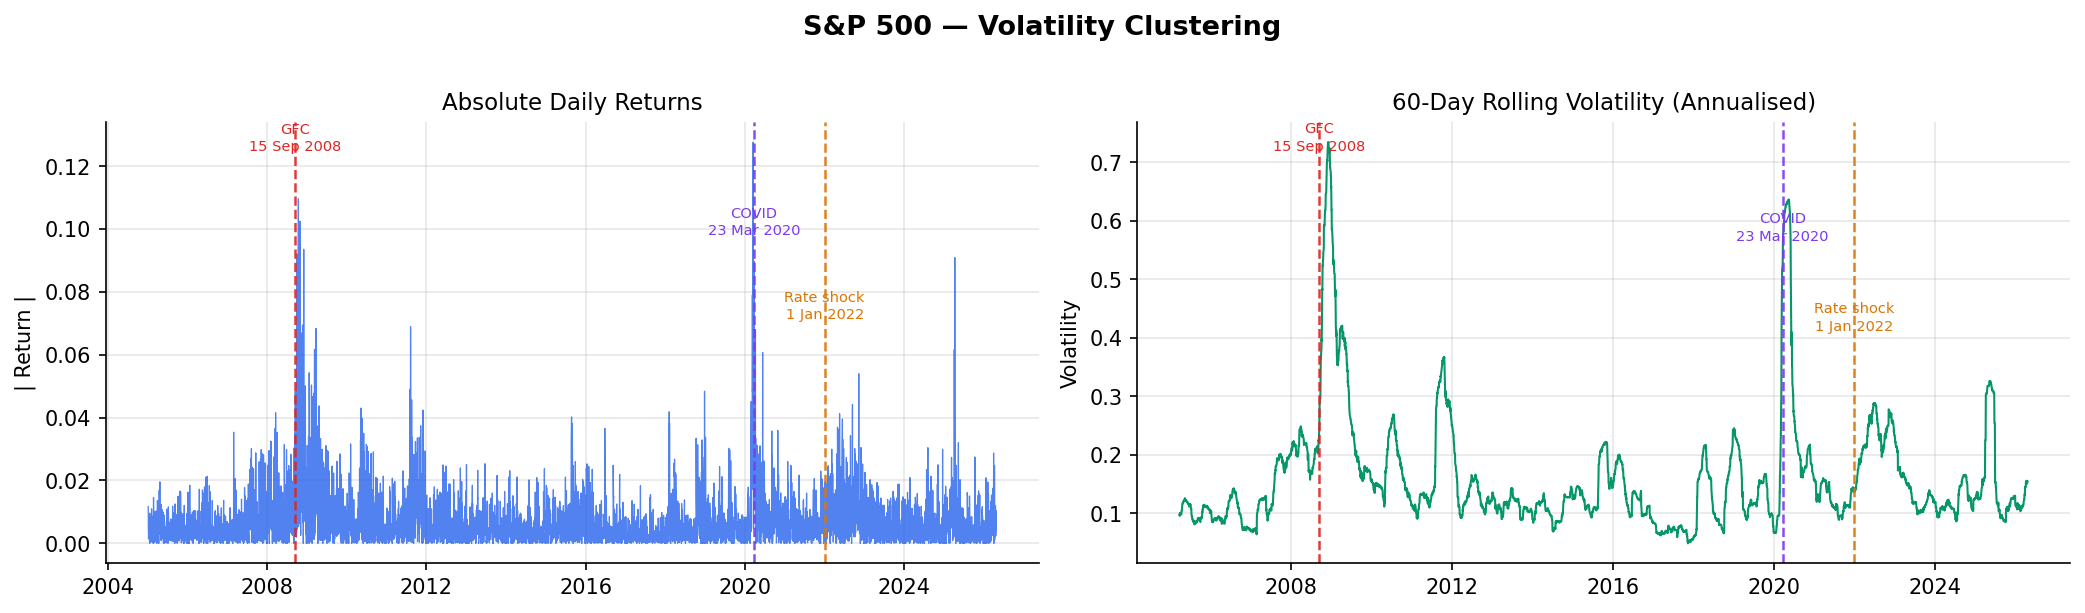

In [9]:
sp500       = returns_daily["sp500"].dropna()
abs_returns = sp500.abs()
rolling_vol = sp500.rolling(60).std() * np.sqrt(252)

crisis_dates = {
    "GFC\n15 Sep 2008"       : "2008-09-15",
    "COVID\n23 Mar 2020"     : "2020-03-23",
    "Rate shock\n1 Jan 2022" : "2022-01-01",
}

crisis_colors = {
    "GFC\n15 Sep 2008"       : "#DC2626",
    "COVID\n23 Mar 2020"     : "#7C3AED",
    "Rate shock\n1 Jan 2022" : "#D97706",
}

label_y_offsets = {
    "GFC\n15 Sep 2008"       : 1.00,
    "COVID\n23 Mar 2020"     : 0.80,
    "Rate shock\n1 Jan 2022" : 0.60,
}

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=False)
fig.suptitle("S&P 500 — Volatility Clustering", fontsize=13, fontweight="bold", y=1.01)

axes[0].plot(abs_returns.index, abs_returns,
             color="#2563EB", linewidth=0.6, alpha=0.8)
axes[0].set_title("Absolute Daily Returns", fontsize=11)
axes[0].set_ylabel("| Return |", fontsize=10)

axes[1].plot(rolling_vol.index, rolling_vol,
             color="#059669", linewidth=1.0)
axes[1].set_title("60-Day Rolling Volatility (Annualised)", fontsize=11)
axes[1].set_ylabel("Volatility", fontsize=10)

for ax in axes:
    ymax = ax.get_ylim()[1]
    for label, date in crisis_dates.items():
        color    = crisis_colors[label]
        y_offset = label_y_offsets[label]
        ax.axvline(pd.Timestamp(date), color=color,
                   linewidth=1.2, linestyle="--", alpha=0.9)
        ax.text(pd.Timestamp(date), ymax * y_offset,
                label, fontsize=7, color=color,
                ha="center", va="top", linespacing=1.3)

for ax in axes:
    ax.xaxis.set_major_locator(mdates.YearLocator(4))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=0, ha="center")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(FIG_DIR / "volatility_clustering.png", dpi=150, bbox_inches="tight")
plt.show()

Both panels confirm pronounced volatility clustering throughout the sample. Crisis episodes are clearly visible as sharp spikes, followed by elevated and persistent volatility before a gradual return to calmer conditions.

## 10. Static Correlation Matrices

Unconditional Pearson correlations are computed separately for the pre-COVID and post-COVID subsamples as a first visual inspection of whether cross-asset co-movement changed. Static correlations average over the entire sub-period and cannot capture time variation, but they provide an immediate directional indication before any dynamic model is applied.

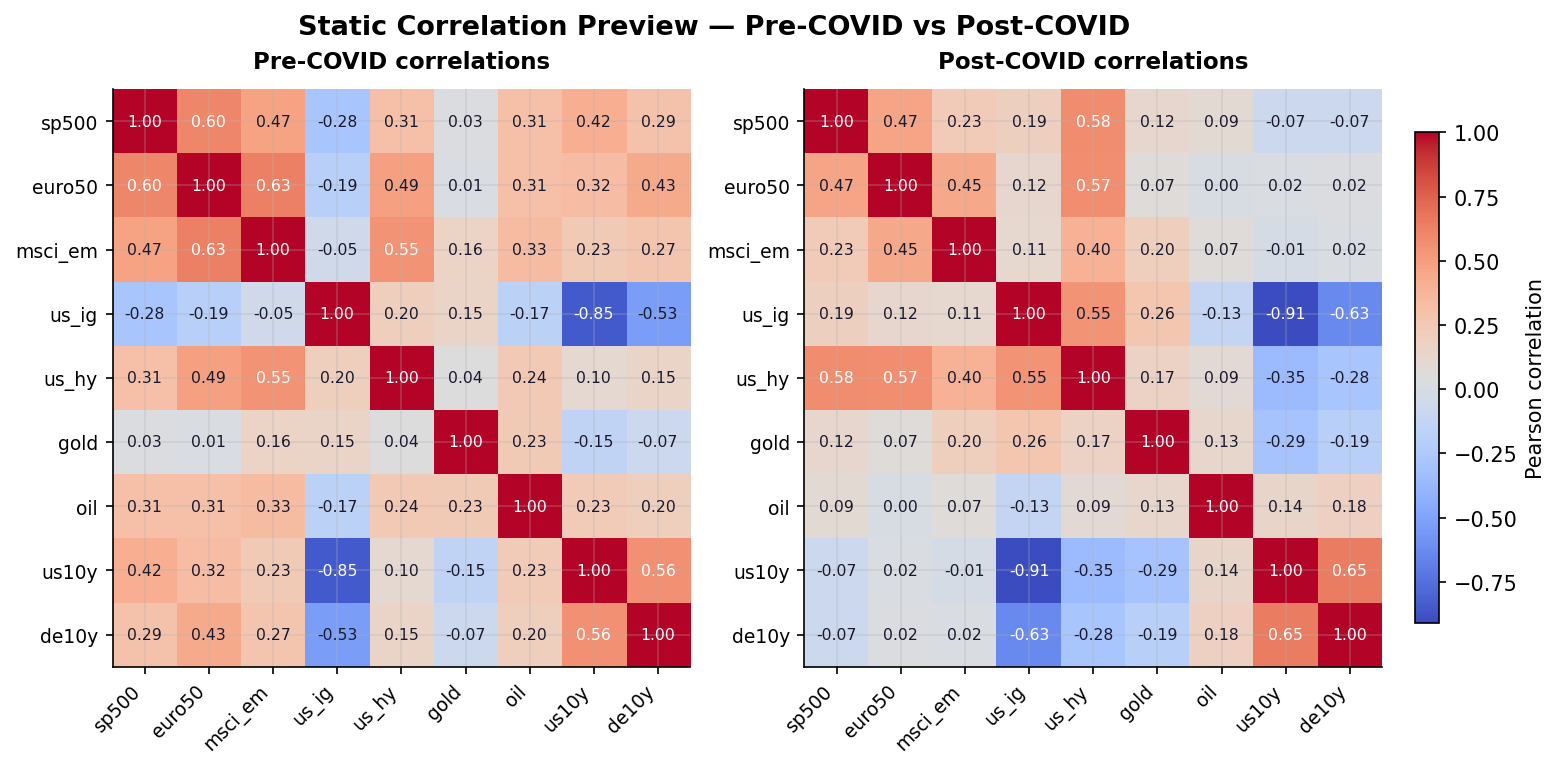

In [10]:
corr_pre  = pre_covid_d.corr(method="pearson")
corr_post = post_covid_d.corr(method="pearson")

corr_pre.to_csv(TAB_DIR  / "corr_pre.csv",  float_format="%.4f")
corr_post.to_csv(TAB_DIR / "corr_post.csv", float_format="%.4f")

vmin = min(corr_pre.min().min(),  corr_post.min().min())
vmax = max(corr_pre.max().max(),  corr_post.max().max())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.subplots_adjust(wspace=0.05)

im0 = axes[0].imshow(corr_pre,  cmap="coolwarm", vmin=vmin, vmax=vmax)
axes[0].set_title("Pre-COVID correlations",  fontsize=11, fontweight="bold", pad=10)

im1 = axes[1].imshow(corr_post, cmap="coolwarm", vmin=vmin, vmax=vmax)
axes[1].set_title("Post-COVID correlations", fontsize=11, fontweight="bold", pad=10)

for ax, corr_matrix in zip(axes, [corr_pre, corr_post]):
    ax.set_xticks(range(len(corr_matrix.columns)))
    ax.set_yticks(range(len(corr_matrix.index)))
    ax.set_xticklabels(corr_matrix.columns, rotation=45, ha="right", fontsize=9)
    ax.set_yticklabels(corr_matrix.index, fontsize=9)

    for i in range(corr_matrix.shape[0]):
        for j in range(corr_matrix.shape[1]):
            val        = corr_matrix.iloc[i, j]
            text_color = "white" if abs(val) > 0.55 else "#1a1a2e"
            ax.text(j, i, f"{val:.2f}",
                    ha="center", va="center",
                    fontsize=7.5, color=text_color)

cbar = fig.colorbar(im1, ax=axes, shrink=0.85, pad=0.02)
cbar.set_label("Pearson correlation", fontsize=10)

fig.suptitle("Static Correlation Preview — Pre-COVID vs Post-COVID",
             fontsize=13, fontweight="bold", ha="center", x=0.45)

fig.savefig(FIG_DIR / "static_correlation_heatmaps.png", dpi=150, bbox_inches="tight")
plt.show()

The two heatmaps share a common color scale for direct comparison. Deeper red indicates stronger positive correlation and deeper blue indicates stronger negative correlation. Changes in the stock-bond relationship are of particular interest for the main research question.

## 11. GARCH Order Selection

Four candidate volatility models are estimated for each asset and ranked by the Bayesian Information Criterion:

$$BIC = k \ln(n) - 2\ell$$

where $k$ is the number of parameters, $n$ the number of observations and $\ell$ the log-likelihood. The candidates are ARCH(1), ARCH(2), GARCH(1,1) and GARCH(2,1). The likelihood is maximised from scratch using L-BFGS-B with an unconstrained parameterisation — exponential and softmax transforms enforce $\omega > 0$ and $\sum \alpha_i + \sum \beta_j < 1$ without box constraints.

In [11]:
def transform_garch(params, p, q):
    mu      = params[0]
    omega   = np.exp(np.clip(params[1], -20, 20))
    raw     = np.clip(params[2:2 + p + q], -20, 20)
    exp_raw = np.exp(raw)
    denom   = 1.0 + exp_raw.sum()
    scaled  = exp_raw / denom
    alphas  = scaled[:p]
    betas   = scaled[p:]
    return mu, omega, alphas, betas


def garch_recursion(eps, omega, alphas, betas):
    p, q         = len(alphas), len(betas)
    T            = len(eps)
    sigma2        = np.empty(T)
    unconditional = np.var(eps)
    sigma2[:]     = unconditional

    for t in range(1, T):
        arch_part  = sum(alphas[i] * eps[t - i - 1] ** 2 for i in range(min(p, t)))
        garch_part = sum(betas[j]  * sigma2[t - j - 1]   for j in range(min(q, t)))
        sigma2[t]  = omega + arch_part + garch_part
        sigma2[t]  = max(sigma2[t], 1e-8)

    return sigma2


def garch_negloglik(params, r, p, q):
    mu, omega, alphas, betas = transform_garch(params, p, q)
    eps    = np.asarray(r) - mu
    sigma2 = garch_recursion(eps, omega, alphas, betas)
    ll     = -0.5 * (np.log(2 * np.pi) + np.log(sigma2) + eps ** 2 / sigma2)
    nll    = -ll.sum()
    return float(nll) if np.isfinite(nll) else 1e12


def fit_garch(r, p, q, maxiter=500):
    r    = np.asarray(r)
    mu0  = r.mean()
    var0 = r.var()

    n_coef   = p + q
    a0       = min(0.15 / max(n_coef, 1), 0.09)
    leftover = max(1 - n_coef * a0, 1e-3)
    phi0     = np.log(a0 / leftover)
    alpha0   = 0.05
    beta0    = 0.90
    x0       = np.r_[mu0, np.log(max(var0 * (1 - alpha0 - beta0), 1e-6)),
                     np.repeat(phi0, n_coef)]

    res = opt.minimize(
        garch_negloglik, x0, args=(r, p, q),
        method="L-BFGS-B", options={"maxiter": maxiter},
    )

    mu, omega, alphas, betas = transform_garch(res.x, p, q)
    eps         = r - mu
    sigma2      = garch_recursion(eps, omega, alphas, betas)
    loglik      = -garch_negloglik(res.x, r, p, q)
    persistence = float(alphas.sum() + betas.sum())

    return {
        "p": p, "q": q, "mu": mu, "omega": omega,
        "alphas": alphas, "betas": betas,
        "persistence": persistence, "eps": eps,
        "sigma2": sigma2, "loglik": loglik, "success": res.success,
    }


CANDIDATES = {
    "ARCH(1)"   : (1, 0),
    "ARCH(2)"   : (2, 0),
    "GARCH(1,1)": (1, 1),
    "GARCH(2,1)": (2, 1),
}

records = []

for asset in returns_model.columns:
    r = returns_model[asset].dropna().values * 100
    n = len(r)

    for label, (p, q) in CANDIDATES.items():
        try:
            fit = fit_garch(r, p, q)
            k   = 2 + p + q
            bic = np.log(n) * k - 2 * fit["loglik"]
            records.append({
                "asset": asset, "model": label, "p": p, "q": q,
                "loglik": fit["loglik"], "BIC": bic,
                "persistence": fit["persistence"], "success": fit["success"],
            })
        except Exception as exc:
            records.append({
                "asset": asset, "model": label, "p": p, "q": q,
                "loglik": np.nan, "BIC": np.nan,
                "persistence": np.nan, "success": False, "error": str(exc),
            })

order_table = pd.DataFrame(records)
order_table.to_csv(TAB_DIR / "garch_order_selection.csv", index=False)

summary_rows = []
for asset, grp in order_table.groupby("asset"):
    valid = grp.dropna(subset=["BIC"])
    valid = valid[valid["persistence"] < 0.999]
    valid = valid.sort_values("BIC")
    if valid.empty:
        # fallback: take best without persistence filter
        valid = grp.dropna(subset=["BIC"]).sort_values("BIC")
    if valid.empty:
        summary_rows.append({
            "asset": asset, "selected_model": "GARCH(1,1)",
            "BIC": np.nan, "persistence": np.nan,
            "note": "No converged candidate — fallback to GARCH(1,1)",
        })
        continue
    best = valid.iloc[0]
    summary_rows.append({
        "asset": asset, "selected_model": best["model"],
        "BIC": best["BIC"], "persistence": best["persistence"],
        "note": "Selected model differs from GARCH(1,1)" if best["model"] != "GARCH(1,1)" else "",
    })

summary_df = pd.DataFrame(summary_rows).set_index("asset").loc[MODEL_ASSETS]
summary_df.to_csv(TAB_DIR / "garch_order_summary.csv")

sep = "-" * 55
print(sep)
print("  GARCH Order Selection")
print(sep)
print(summary_df.to_string())

-------------------------------------------------------
  GARCH Order Selection
-------------------------------------------------------
                 selected_model           BIC  persistence                                    note
asset                                                                                             
sp500                GARCH(1,1)  14636.707332     0.976814                                        
euro50               GARCH(2,1)  16872.378254     0.975137  Selected model differs from GARCH(1,1)
msci_em              GARCH(1,1)  15733.643676     0.976825                                        
us_ig                GARCH(1,1)   2109.319513     0.991520                                        
us_hy                   ARCH(2)   -864.755812     0.971851  Selected model differs from GARCH(1,1)
gold                 GARCH(2,1)  15796.684652     0.988306  Selected model differs from GARCH(1,1)
oil                  GARCH(2,1)  24094.468363     0.986551  Selected mod

The table reports the BIC-selected model and the corresponding persistence $\alpha + \beta$ for each asset. Persistence close to 1 indicates that volatility shocks decay slowly.

## 12. Full-Sample GARCH Estimation

GARCH models are estimated for all nine assets on the full sample using Student-$t$ innovations. The Student-$t$ log-likelihood is:

$$\ell_t = \log\Gamma\!\left(\frac{\nu+1}{2}\right) - \log\Gamma\!\left(\frac{\nu}{2}\right) - \frac{1}{2}\log\left[(\nu-2)\pi\sigma^2_t\right] - \frac{\nu+1}{2}\log\!\left(1 + \frac{z_t^2}{\nu-2}\right)$$

where $z_t = \varepsilon_t / \sigma_t$ and $\nu > 2$ is the degrees-of-freedom parameter estimated jointly with the GARCH coefficients. The selected order from the previous step is used for each asset, falling back to GARCH(1,1) if unavailable.

In [12]:
from scipy.special import gammaln


def parse_selected_order(model_name):
    mapping = {
        "ARCH(1)": (1, 0),
        "ARCH(2)": (2, 0),
        "GARCH(1,1)": (1, 1),
        "GARCH(2,1)": (2, 1),
    }
    return mapping.get(model_name, (1, 1))


def garch_t_loglik(theta, r, p, q):
    mu = theta[0]
    omega = np.exp(theta[1])
    raw = np.clip(theta[2:2 + p + q], -20, 20)
    exp_raw = np.exp(raw)
    denom = 1.0 + exp_raw.sum()
    scaled = exp_raw / denom
    alphas = scaled[:p]
    betas = scaled[p:]
    nu = 2.1 + np.exp(np.clip(theta[-1], -20, 20))

    eps = np.asarray(r) - mu
    sigma2 = garch_recursion(eps, omega, alphas, betas)
    z = eps / np.sqrt(sigma2)

    c = (
        gammaln((nu + 1) / 2)
        - gammaln(nu / 2)
        - 0.5 * np.log((nu - 2) * np.pi)
    )
    ll = c - 0.5 * np.log(sigma2) - ((nu + 1) / 2) * np.log(1 + z ** 2 / (nu - 2))
    nll = -ll.sum()
    return float(nll) if np.isfinite(nll) else 1e12


def fit_garch_t(r, p, q):
    """Fit GARCH(p,q) with standardised Student-t innovations."""
    r = np.asarray(r)
    mu0 = r.mean()
    var0 = r.var()
    n_coef = p + q
    a0 = min(0.15 / max(n_coef, 1), 0.09)
    leftover = max(1 - n_coef * a0, 1e-3)
    phi0 = np.log(a0 / leftover)
    alpha0 = 0.05
    beta0  = 0.90
    x0     = np.r_[mu0, np.log(max(var0 * (1 - alpha0 - beta0), 1e-6)),
                   np.repeat(phi0, n_coef), np.log(8 - 2.1)]

    res = opt.minimize(
        garch_t_loglik,
        x0,
        args=(r, p, q),
        method="L-BFGS-B",
        options={"maxiter": 700},
    )

    mu = res.x[0]
    omega = np.exp(res.x[1])
    raw = np.clip(res.x[2:2 + p + q], -20, 20)
    exp_raw = np.exp(raw)
    denom = 1.0 + exp_raw.sum()
    scaled = exp_raw / denom
    alphas = scaled[:p]
    betas = scaled[p:]
    nu = 2.1 + np.exp(np.clip(res.x[-1], -20, 20))

    eps = r - mu
    sigma2 = garch_recursion(eps, omega, alphas, betas)
    z = eps / np.sqrt(sigma2)

    return {
        "mu": mu,
        "omega": omega,
        "alphas": alphas,
        "betas": betas,
        "nu": nu,
        "eps": eps,
        "sigma2": sigma2,
        "z": z,
        "success": res.success,
        "message": res.message,
    }


selected_orders = {}
if "summary_df" in globals():
    for asset in returns_model.columns:
        model_name = summary_df.loc[asset, "selected_model"] if asset in summary_df.index else "GARCH(1,1)"
        selected_orders[asset] = parse_selected_order(model_name)
else:
    selected_orders = {asset: (1, 1) for asset in returns_model.columns}

garch_fits = {}
full_rows = []

for asset in returns_model.columns:
    p, q = selected_orders.get(asset, (1, 1))
    r = returns_model[asset].dropna().values * 100
    fit = fit_garch_t(r, p, q)
    garch_fits[asset] = fit

    alpha_sum = float(np.sum(fit["alphas"])) if len(fit["alphas"]) else 0.0
    beta_sum = float(np.sum(fit["betas"])) if len(fit["betas"]) else 0.0

    full_rows.append({
        "asset": asset,
        "model": f"GARCH({p},{q})",
        "dist": "Student-t",
        "mu": fit["mu"],
        "omega": fit["omega"],
        "alpha_sum": alpha_sum,
        "beta_sum": beta_sum,
        "alpha+beta": alpha_sum + beta_sum,
        "nu": fit["nu"],
        "success": fit["success"],
        "message": str(fit["message"]),
    })

garch_full_table = pd.DataFrame(full_rows).set_index("asset").loc[MODEL_ASSETS]
garch_full_table.to_csv("Tables/garch_full_table.csv")

print("STEP 8A -- FULL-SAMPLE GARCH ON RETURNS_MODEL")
print()
print(garch_full_table.to_string())
print()
print("Saved: Tables/garch_full_table.csv")
print(f"garch_fits ready for {len(garch_fits)} assets")

STEP 8A -- FULL-SAMPLE GARCH ON RETURNS_MODEL

                       model       dist        mu     omega  alpha_sum  beta_sum  alpha+beta         nu  success                                               message
asset                                                                                                                                                                 
sp500             GARCH(1,1)  Student-t  0.084573  0.016626   0.136957  0.863042    0.999999   4.732152     True  CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
euro50            GARCH(2,1)  Student-t  0.069337  0.035521   0.131326  0.854935    0.986261   5.332603     True  CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
msci_em           GARCH(1,1)  Student-t  0.067748  0.027117   0.097112  0.881420    0.978531   7.807497     True  CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
us_ig             GARCH(1,1)  Student-t  0.022108  0.000848   0.050698  0.940960    0.991658   9.488545     True  CONV

The table reports estimated parameters, persistence $\alpha + \beta$ and degrees of freedom $\nu$ for each asset. Convergence status is shown in the final column.

## 13. Pre/Post COVID GARCH Comparison

GARCH(1,1) with Student-$t$ innovations is re-estimated separately on the pre-COVID and post-COVID subsamples for all nine assets. A common GARCH(1,1) specification is used across all assets regardless of the BIC selection in the previous step, ensuring that parameter changes are attributable to the data rather than to model differences. The key quantity of interest is the change in persistence $\alpha + \beta$ between the two subsamples.

In [13]:
P_BENCH, Q_BENCH = 1, 1

periods = {
    "pre" : pre_covid_model,
    "post": post_covid_model,
}

pre_post_fits = {asset: {} for asset in returns_model.columns}
rows          = []

for period_name, df_period in periods.items():
    for asset in returns_model.columns:
        r   = df_period[asset].dropna().values * 100
        fit = fit_garch_t(r, P_BENCH, Q_BENCH)
        pre_post_fits[asset][period_name] = fit

        alpha_sum = float(np.sum(fit["alphas"])) if len(fit["alphas"]) else 0.0
        beta_sum  = float(np.sum(fit["betas"]))  if len(fit["betas"])  else 0.0

        rows.append({
            "asset"     : asset,
            "period"    : period_name,
            "start"     : df_period.index.min().date(),
            "end"       : df_period.index.max().date(),
            "n_obs"     : len(r),
            "mu"        : fit["mu"],
            "omega"     : fit["omega"],
            "alpha_sum" : alpha_sum,
            "beta_sum"  : beta_sum,
            "alpha+beta": alpha_sum + beta_sum,
            "nu"        : fit["nu"],
            "success"   : fit["success"],
        })

garch_pre_post_table = pd.DataFrame(rows)
garch_pre_post_table.to_csv(TAB_DIR / "garch_pre_post_table.csv", index=False)

sep = "-" * 55
print(sep)
print("  Pre/Post GARCH(1,1) — Student-t")
print(sep)
print(f"  Pre-COVID  : {pre_covid_model.index.min().date()} to "
      f"{pre_covid_model.index.max().date()}")
print(f"  Post-COVID : {post_covid_model.index.min().date()} to "
      f"{post_covid_model.index.max().date()}")
print(sep)
print(garch_pre_post_table.to_string(index=False))

-------------------------------------------------------
  Pre/Post GARCH(1,1) — Student-t
-------------------------------------------------------
  Pre-COVID  : 2005-01-04 to 2019-12-31
  Post-COVID : 2021-01-01 to 2026-04-24
-------------------------------------------------------
           asset period      start        end  n_obs        mu    omega  alpha_sum  beta_sum  alpha+beta           nu  success
           sp500    pre 2005-01-04 2019-12-31   3911  0.076126 0.013671   0.127403  0.872597    1.000000     4.534935     True
          euro50    pre 2005-01-04 2019-12-31   3911  0.061232 0.017655   0.108851  0.891145    0.999995     5.481554     True
         msci_em    pre 2005-01-04 2019-12-31   3911  0.072515 0.017805   0.089628  0.896849    0.986477     8.747783     True
           us_ig    pre 2005-01-04 2019-12-31   3911  0.022706 0.000415   0.032619  0.962248    0.994868    10.694504     True
           us_hy    pre 2005-01-04 2019-12-31   3911  0.045478 0.001437   0.319255 

The table reports estimated parameters for each asset and each subsample side by side. Changes in persistence and the degrees-of-freedom parameter $\nu$ across the two periods are the primary indicators of whether the volatility structure has shifted since COVID.

## 14. Standardised Residuals

Once GARCH is estimated, each return series is decomposed into a time-varying conditional volatility $\sigma_t$ and a pure shock $z_t$:

$$z_t = \frac{\varepsilon_t}{\sigma_t} = \frac{r_t - \mu}{\sigma_t}$$

The standardised residuals remove the GARCH volatility component and are used as input for the DCC filter in the next step. If they are properly standardised, their variance should be close to 1 throughout the sample.

In [14]:
std_resid = pd.DataFrame(index=returns_model.index)

for asset in MODEL_ASSETS:
    fit           = garch_fits[asset]
    asset_series  = returns_model[asset].dropna()
    aligned_index = asset_series.index[-len(fit["z"]):]
    std_resid.loc[aligned_index, asset] = fit["z"]

std_resid = std_resid[MODEL_ASSETS]
std_resid.to_csv(TAB_DIR / "std_resid_daily.csv")

sep = "-" * 55
print(sep)
print("  Standardised Residuals")
print(sep)
print(std_resid.head().to_string())
print(sep)
print("Missing values:")
print(std_resid.isna().sum().to_string())

-------------------------------------------------------
  Standardised Residuals
-------------------------------------------------------
               sp500    euro50   msci_em     us_ig     us_hy      gold       oil  us10y_bond_proxy  de10y_bond_proxy
2005-01-04 -1.064003 -0.024792 -1.530262 -1.194028 -0.017643 -0.467023  1.576869         -1.372482         -0.326622
2005-01-05 -0.373197 -0.720022 -1.215263  0.117201 -1.981773 -0.262708 -0.459515          0.135715         -0.036822
2005-01-06  0.233863  0.488963 -1.095404 -0.111377 -0.543355 -1.194920  1.810122          0.347505          0.661867
2005-01-07 -0.213560  0.343046  0.053726 -0.192265 -0.293576 -0.579146 -0.123473         -0.139070          0.339537
2005-01-10  0.255560 -0.146264  0.086507  0.153873 -0.803076  0.084191 -0.105344          0.001827          0.418458
-------------------------------------------------------
Missing values:
sp500               0
euro50              0
msci_em             0
us_ig               0
u

## 15. Rolling Correlations

Rolling Pearson correlations are computed on weekly returns using a 52-week window for six economically meaningful pairs, all involving the S&P 500. Rolling correlations reveal how co-movement evolved continuously through the sample, capturing regime changes that static correlations average away. Pre- and post-COVID period means are shown as reference lines on each panel, and a Welch t-test formally tests whether the mean correlation shifted significantly between the two subsamples.

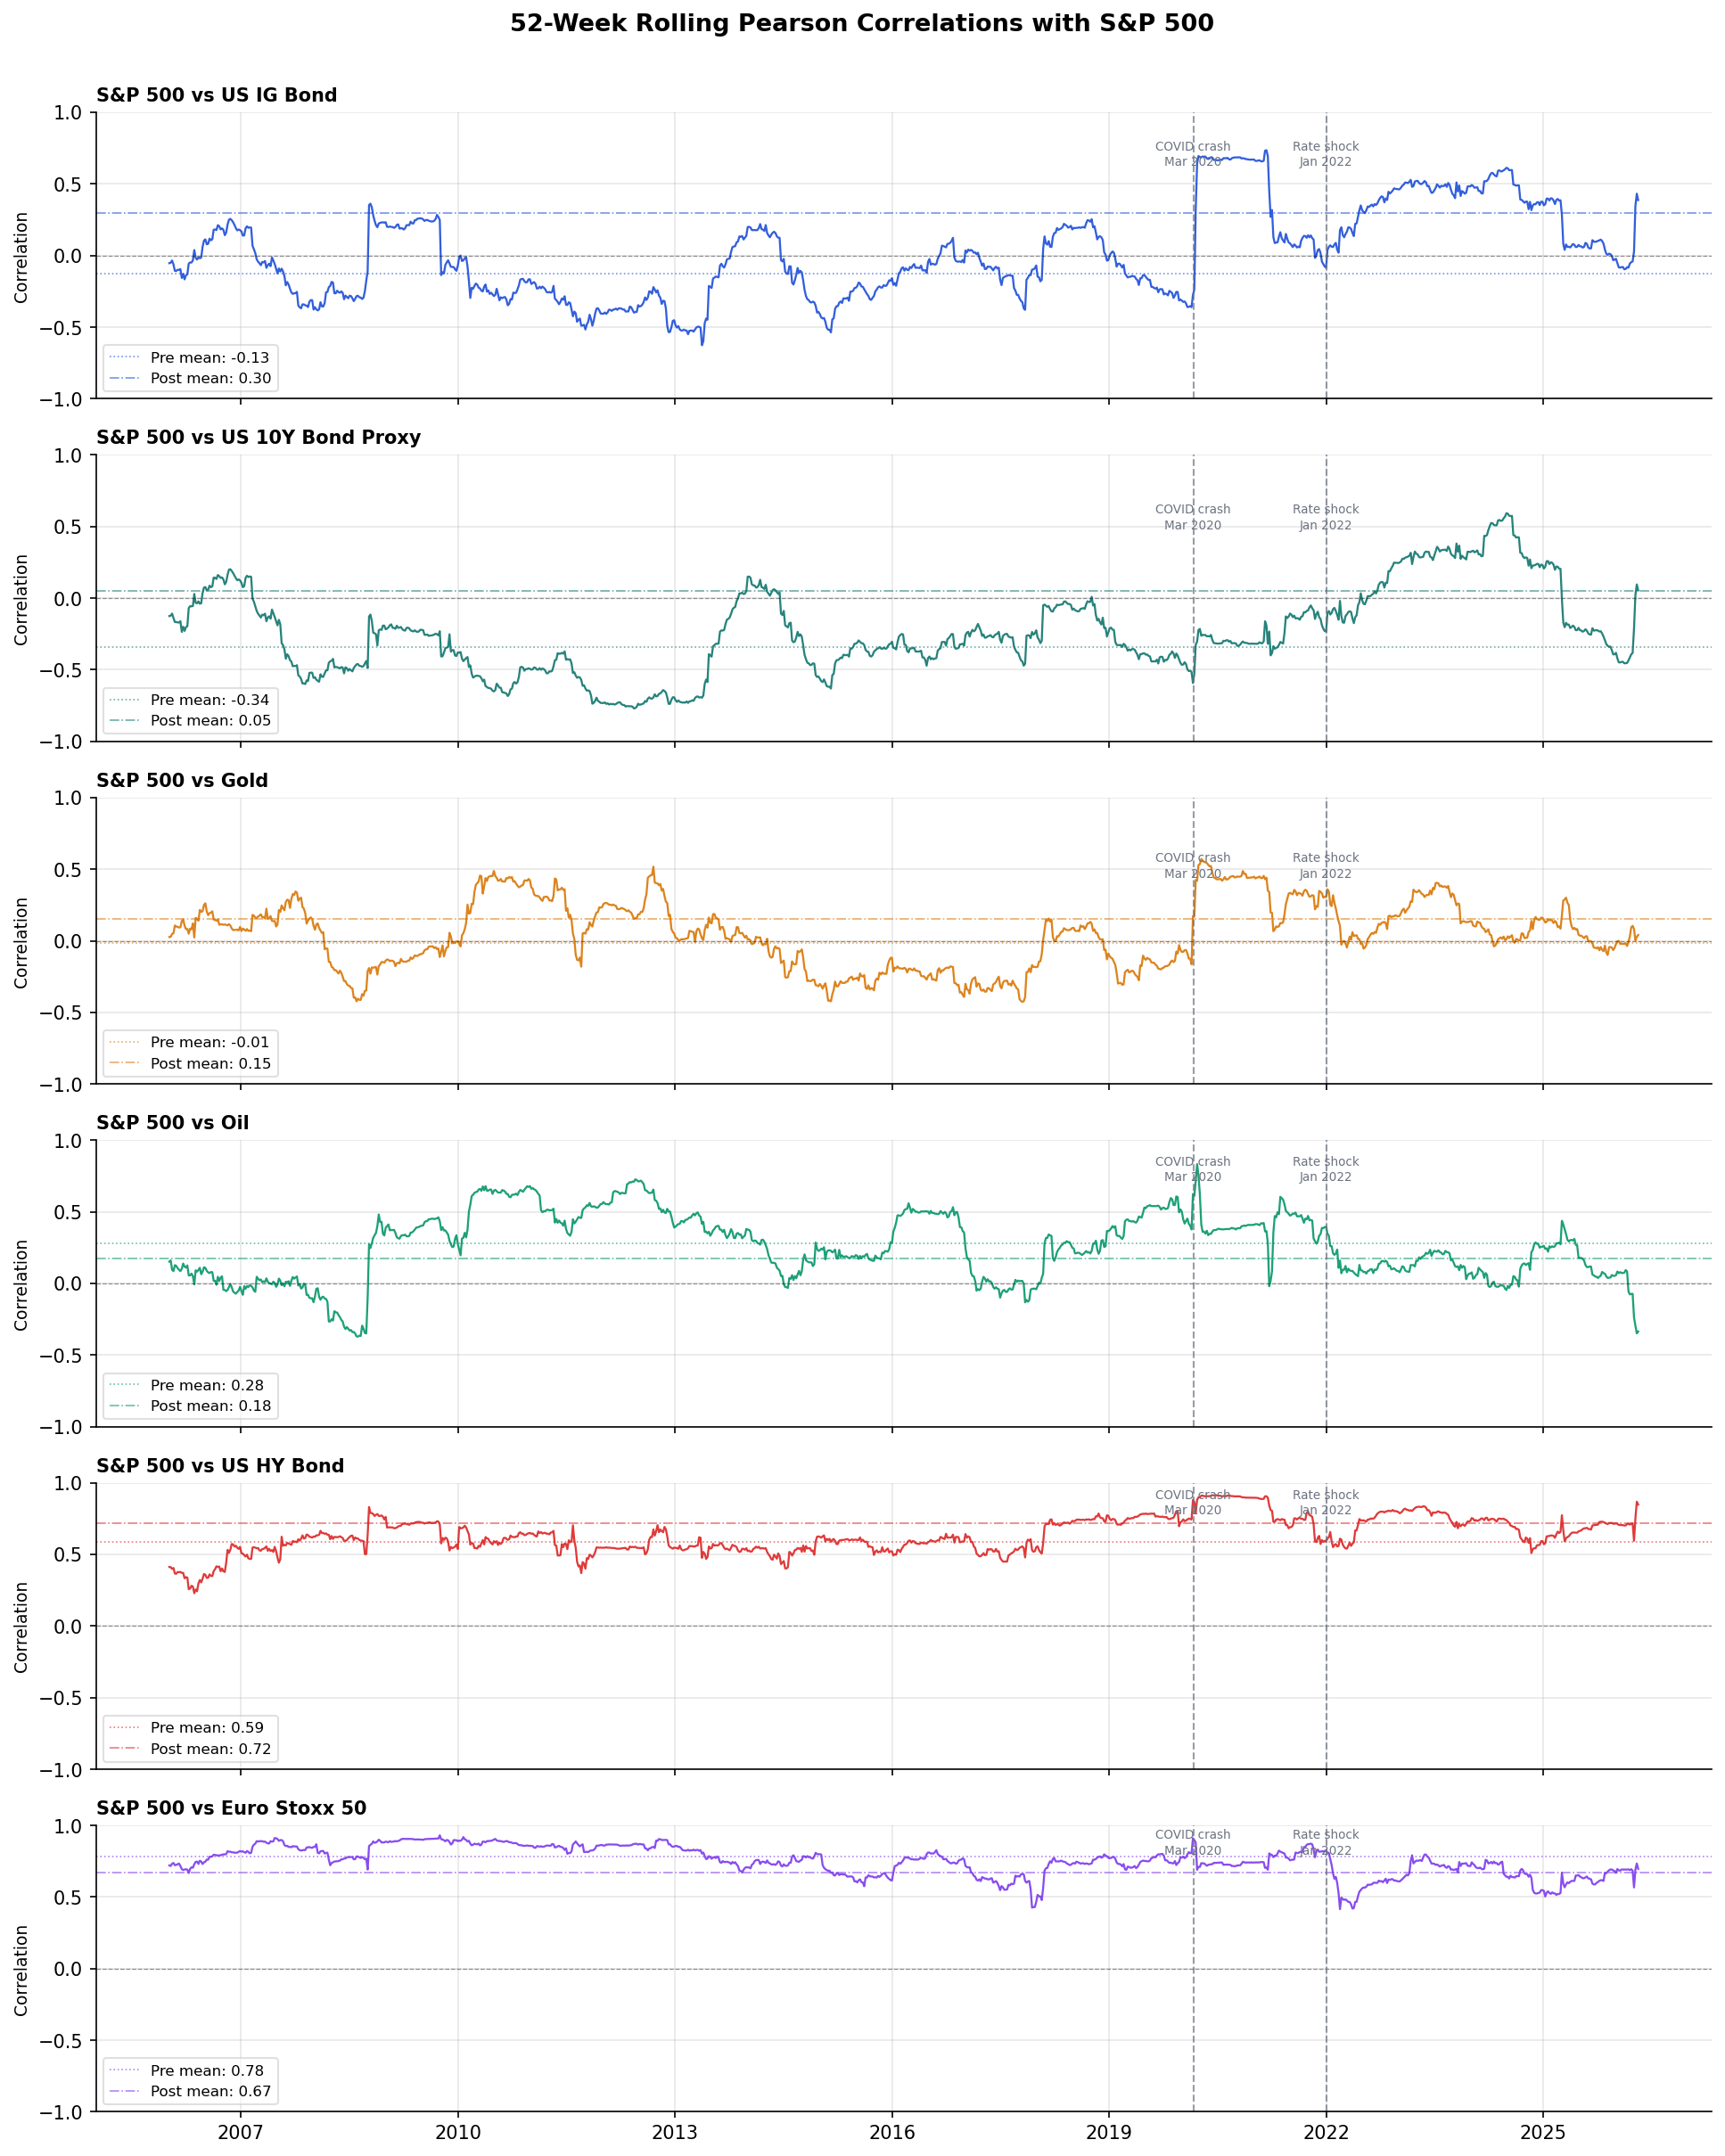

-------------------------------------------------------
  Rolling Correlation — Pre vs Post COVID
  Window : 52 weeks
  Pre    : up to 2019-12-31   Post: from 2021-01-01
-------------------------------------------------------
                   pre_mean  post_mean   delta   t_stat   p_value note significant
pair                                                                              
sp500_us_ig         -0.1257     0.2999  0.4255 -28.0816  < 0.0001              Yes
sp500_us10y_proxy   -0.3420     0.0484  0.3904 -20.4537  < 0.0001              Yes
sp500_gold          -0.0125     0.1517  0.1642 -13.5404  < 0.0001              Yes
sp500_oil            0.2818     0.1763 -0.1054   7.8634  < 0.0001              Yes
sp500_us_hy          0.5886     0.7153  0.1267 -19.7492  < 0.0001              Yes
sp500_euro50         0.7806     0.6731 -0.1075  15.9055  < 0.0001              Yes


In [15]:
PAIRS = {
    "sp500_us_ig"       : ("sp500", "us_ig"),
    "sp500_us10y_proxy" : ("sp500", "us10y_bond_proxy"),
    "sp500_gold"        : ("sp500", "gold"),
    "sp500_oil"         : ("sp500", "oil"),
    "sp500_us_hy"       : ("sp500", "us_hy"),
    "sp500_euro50"      : ("sp500", "euro50"),
}

PAIR_LABELS = {
    "sp500_us_ig"       : "S&P 500 vs US IG Bond",
    "sp500_us10y_proxy" : "S&P 500 vs US 10Y Bond Proxy",
    "sp500_gold"        : "S&P 500 vs Gold",
    "sp500_oil"         : "S&P 500 vs Oil",
    "sp500_us_hy"       : "S&P 500 vs US HY Bond",
    "sp500_euro50"      : "S&P 500 vs Euro Stoxx 50",
}

WINDOW = 52

rolling_corr = pd.DataFrame(index=returns_model_weekly.index)

for pair_name, (a1, a2) in PAIRS.items():
    rolling_corr[pair_name] = (
        returns_model_weekly[a1]
        .rolling(WINDOW)
        .corr(returns_model_weekly[a2])
    )

rolling_corr.index.name = "date"
rolling_corr.to_csv(TAB_DIR / "rolling_corr_pairs.csv")

BREAK_DATES = {
    "COVID crash\nMar 2020" : "2020-03-01",
    "Rate shock\nJan 2022"  : "2022-01-01",
}

COLORS = {
    "sp500_us_ig"       : "#1D4ED8",
    "sp500_us10y_proxy" : "#0F766E",
    "sp500_gold"        : "#D97706",
    "sp500_oil"         : "#059669",
    "sp500_us_hy"       : "#DC2626",
    "sp500_euro50"      : "#7C3AED",
}

fig, axes = plt.subplots(len(PAIRS), 1, figsize=(13, 16), sharex=True)
fig.suptitle("52-Week Rolling Pearson Correlations with S&P 500",
             fontsize=13, fontweight="bold", y=1.005)

for ax, (pair_name, _) in zip(axes, PAIRS.items()):
    series    = rolling_corr[pair_name].dropna()
    color     = COLORS[pair_name]
    pre_mean  = rolling_corr[pair_name].loc[:PRE_END].mean()
    post_mean = rolling_corr[pair_name].loc[POST_START:].mean()

    ax.plot(series.index, series, color=color, linewidth=1.1, alpha=0.9)
    ax.axhline(0,         color="black", linewidth=0.6, linestyle="--", alpha=0.4)
    ax.axhline(pre_mean,  color=color,   linewidth=0.8, linestyle=":",  alpha=0.6,
               label=f"Pre mean: {pre_mean:.2f}")
    ax.axhline(post_mean, color=color,   linewidth=0.8, linestyle="-.", alpha=0.6,
               label=f"Post mean: {post_mean:.2f}")

    for label, date in BREAK_DATES.items():
        ax.axvline(pd.Timestamp(date), color="#6B7280",
                   linewidth=1.0, linestyle="--", alpha=0.7)
        ax.text(pd.Timestamp(date),
                ax.get_ylim()[1] if ax.get_ylim()[1] != 1.0 else 0.95,
                label, fontsize=6.5, color="#6B7280",
                ha="center", va="top", linespacing=1.3)

    ax.set_ylabel("Correlation", fontsize=9)
    ax.set_title(PAIR_LABELS[pair_name], fontsize=10, fontweight="bold", loc="left")
    ax.legend(fontsize=8, loc="lower left", framealpha=0.6)
    ax.set_ylim(-1.0, 1.0)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[-1].xaxis.set_major_locator(mdates.YearLocator(3))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.setp(axes[-1].xaxis.get_majorticklabels(), rotation=0, ha="center")

plt.tight_layout()
plt.savefig(FIG_DIR / "rolling_corr_pairs.png", dpi=150, bbox_inches="tight")
plt.show()

test_records = []

for pair_name in PAIRS:
    pre_series  = rolling_corr[pair_name].loc[:PRE_END].dropna()
    post_series = rolling_corr[pair_name].loc[POST_START:].dropna()

    if len(pre_series) < 10 or len(post_series) < 10:
        test_records.append({
            "pair": pair_name, "pre_mean": np.nan, "post_mean": np.nan,
            "delta": np.nan, "t_stat": np.nan, "p_value": np.nan,
            "note": "insufficient observations",
        })
        continue

    t_stat, p_val = ttest_ind(pre_series, post_series, equal_var=False)
    test_records.append({
        "pair"      : pair_name,
        "pre_mean"  : round(pre_series.mean(),                    4),
        "post_mean" : round(post_series.mean(),                   4),
        "delta"     : round(post_series.mean() - pre_series.mean(), 4),
        "t_stat"    : round(t_stat,                               4),
        "p_value"   : round(p_val,                                6),
        "note"      : "",
    })

corr_tests = pd.DataFrame(test_records).set_index("pair")
corr_tests.to_csv(TAB_DIR / "rolling_corr_tests.csv")

display_tests = corr_tests.copy()
display_tests["p_value"] = corr_tests["p_value"].apply(
    lambda p: "< 0.0001" if p < 0.0001 else
              ("< 0.001"  if p < 0.001  else
              ("< 0.01"   if p < 0.01   else
              ("< 0.05"   if p < 0.05   else f"{p:.4f}")))
)
display_tests["significant"] = corr_tests["p_value"].apply(
    lambda p: "Yes" if p < 0.05 else "No"
)

sep = "-" * 55
print(sep)
print(f"  Rolling Correlation — Pre vs Post COVID")
print(f"  Window : {WINDOW} weeks")
print(f"  Pre    : up to {PRE_END}   Post: from {POST_START}")
print(sep)
print(display_tests.to_string())

The six panels show the evolution of each pairwise correlation from 2005 to the end of the sample. The test table reports the pre- and post-COVID mean, the change in mean and the p-value of the Welch t-test. A significant p-value indicates a statistically meaningful shift in the correlation structure after COVID.

## 16. DCC Dynamic Correlation Filter

The Dynamic Conditional Correlation (DCC) model filters time-varying correlations from the GARCH standardised residuals. The quasi-correlation matrix $Q_t$ evolves as:

$$Q_t = (1 - \theta_1 - \theta_2)\bar{Q} + \theta_1 z_{t-1}z_{t-1}' + \theta_2 Q_{t-1}$$

where $\bar{Q}$ is the unconditional covariance of the standardised residuals and $(\theta_1, \theta_2) = (0.05, 0.93)$. The correlation matrix is recovered by rescaling: $R_t = \text{diag}(Q_t)^{-1/2} Q_t \, \text{diag}(Q_t)^{-1/2}$. The full conditional covariance matrix is $H_t = D_t R_t D_t$ where $D_t$ contains the GARCH conditional volatilities on the diagonal.

In [16]:
theta1, theta2 = 0.05, 0.93

std_resid = std_resid[MODEL_ASSETS].dropna(how="any").copy()
H_ASSETS  = list(std_resid.columns)
Z         = std_resid.values
T, N      = Z.shape

Qbar     = np.corrcoef(Z.T)
Qt       = Qbar.copy()
R_t      = {}
H_t      = {}
dcc_corr = pd.DataFrame(index=std_resid.index)

for t, date in enumerate(std_resid.index):
    if t > 0:
        z_prev = Z[t - 1].reshape(-1, 1)
        Qt     = (1 - theta1 - theta2) * Qbar + theta1 * (z_prev @ z_prev.T) + theta2 * Qt

    diag_q   = np.sqrt(np.clip(np.diag(Qt), 1e-12, None))
    inv_diag = np.diag(1.0 / diag_q)
    Rt       = inv_diag @ Qt @ inv_diag
    Rt       = 0.5 * (Rt + Rt.T)
    np.fill_diagonal(Rt, 1.0)

    vol_vec = []
    for asset in H_ASSETS:
        fit          = garch_fits[asset]
        asset_series = returns_model[asset].dropna()
        loc          = asset_series.index.get_loc(date)
        vol_vec.append(np.sqrt(fit["sigma2"][loc]) / 100.0)

    D_t = np.diag(vol_vec)
    H   = D_t @ Rt @ D_t
    H   = 0.5 * (H + H.T)

    R_t[date] = pd.DataFrame(Rt, index=H_ASSETS, columns=H_ASSETS)
    H_t[date] = pd.DataFrame(H,  index=H_ASSETS, columns=H_ASSETS)

pair_map = {
    "sp500_us_ig"       : ("sp500", "us_ig"),
    "sp500_us10y_proxy" : ("sp500", "us10y_bond_proxy"),
    "sp500_gold"        : ("sp500", "gold"),
    "sp500_oil"         : ("sp500", "oil"),
    "sp500_us_hy"       : ("sp500", "us_hy"),
    "sp500_euro50"      : ("sp500", "euro50"),
}

for label, (a, b) in pair_map.items():
    if a in H_ASSETS and b in H_ASSETS:
        dcc_corr[label] = [R_t[date].loc[a, b] for date in std_resid.index]

dcc_corr.to_csv(TAB_DIR / "dcc_correlations_daily.csv")

sep = "-" * 55
print(sep)
print("  DCC Filter")
print(f"  Assets : {H_ASSETS}")
print(f"  T = {T}, N = {N}")
print(sep)
print(dcc_corr.head().to_string())

-------------------------------------------------------
  DCC Filter
  Assets : ['sp500', 'euro50', 'msci_em', 'us_ig', 'us_hy', 'gold', 'oil', 'us10y_bond_proxy', 'de10y_bond_proxy']
  T = 5557, N = 9
-------------------------------------------------------
            sp500_us_ig  sp500_us10y_proxy  sp500_gold  sp500_oil  sp500_us_hy  sp500_euro50
2005-01-04    -0.136165          -0.263296    0.059639   0.229392     0.417404      0.570219
2005-01-05    -0.064931          -0.172757    0.082871   0.128889     0.406454      0.555294
2005-01-06    -0.068408          -0.176494    0.087137   0.138389     0.403193      0.560025
2005-01-07    -0.071169          -0.173176    0.068058   0.150331     0.393597      0.561973
2005-01-10    -0.070145          -0.173214    0.074062   0.153042     0.396065      0.555286


The first rows of the DCC correlation series confirm that the filter ran successfully for all six pairs. The full daily series is saved for use in the structural break tests and portfolio construction steps.

## 17. DCC Correlation Charts

The six panels plot the daily DCC-filtered conditional correlations between the S&P 500 and each asset. Unlike rolling correlations, these are computed on GARCH standardised residuals and therefore reflect pure co-movement stripped of individual volatility effects. Shaded regions above and below zero highlight positive and negative correlation regimes. Pre- and post-COVID averages are shown as reference lines on each panel.

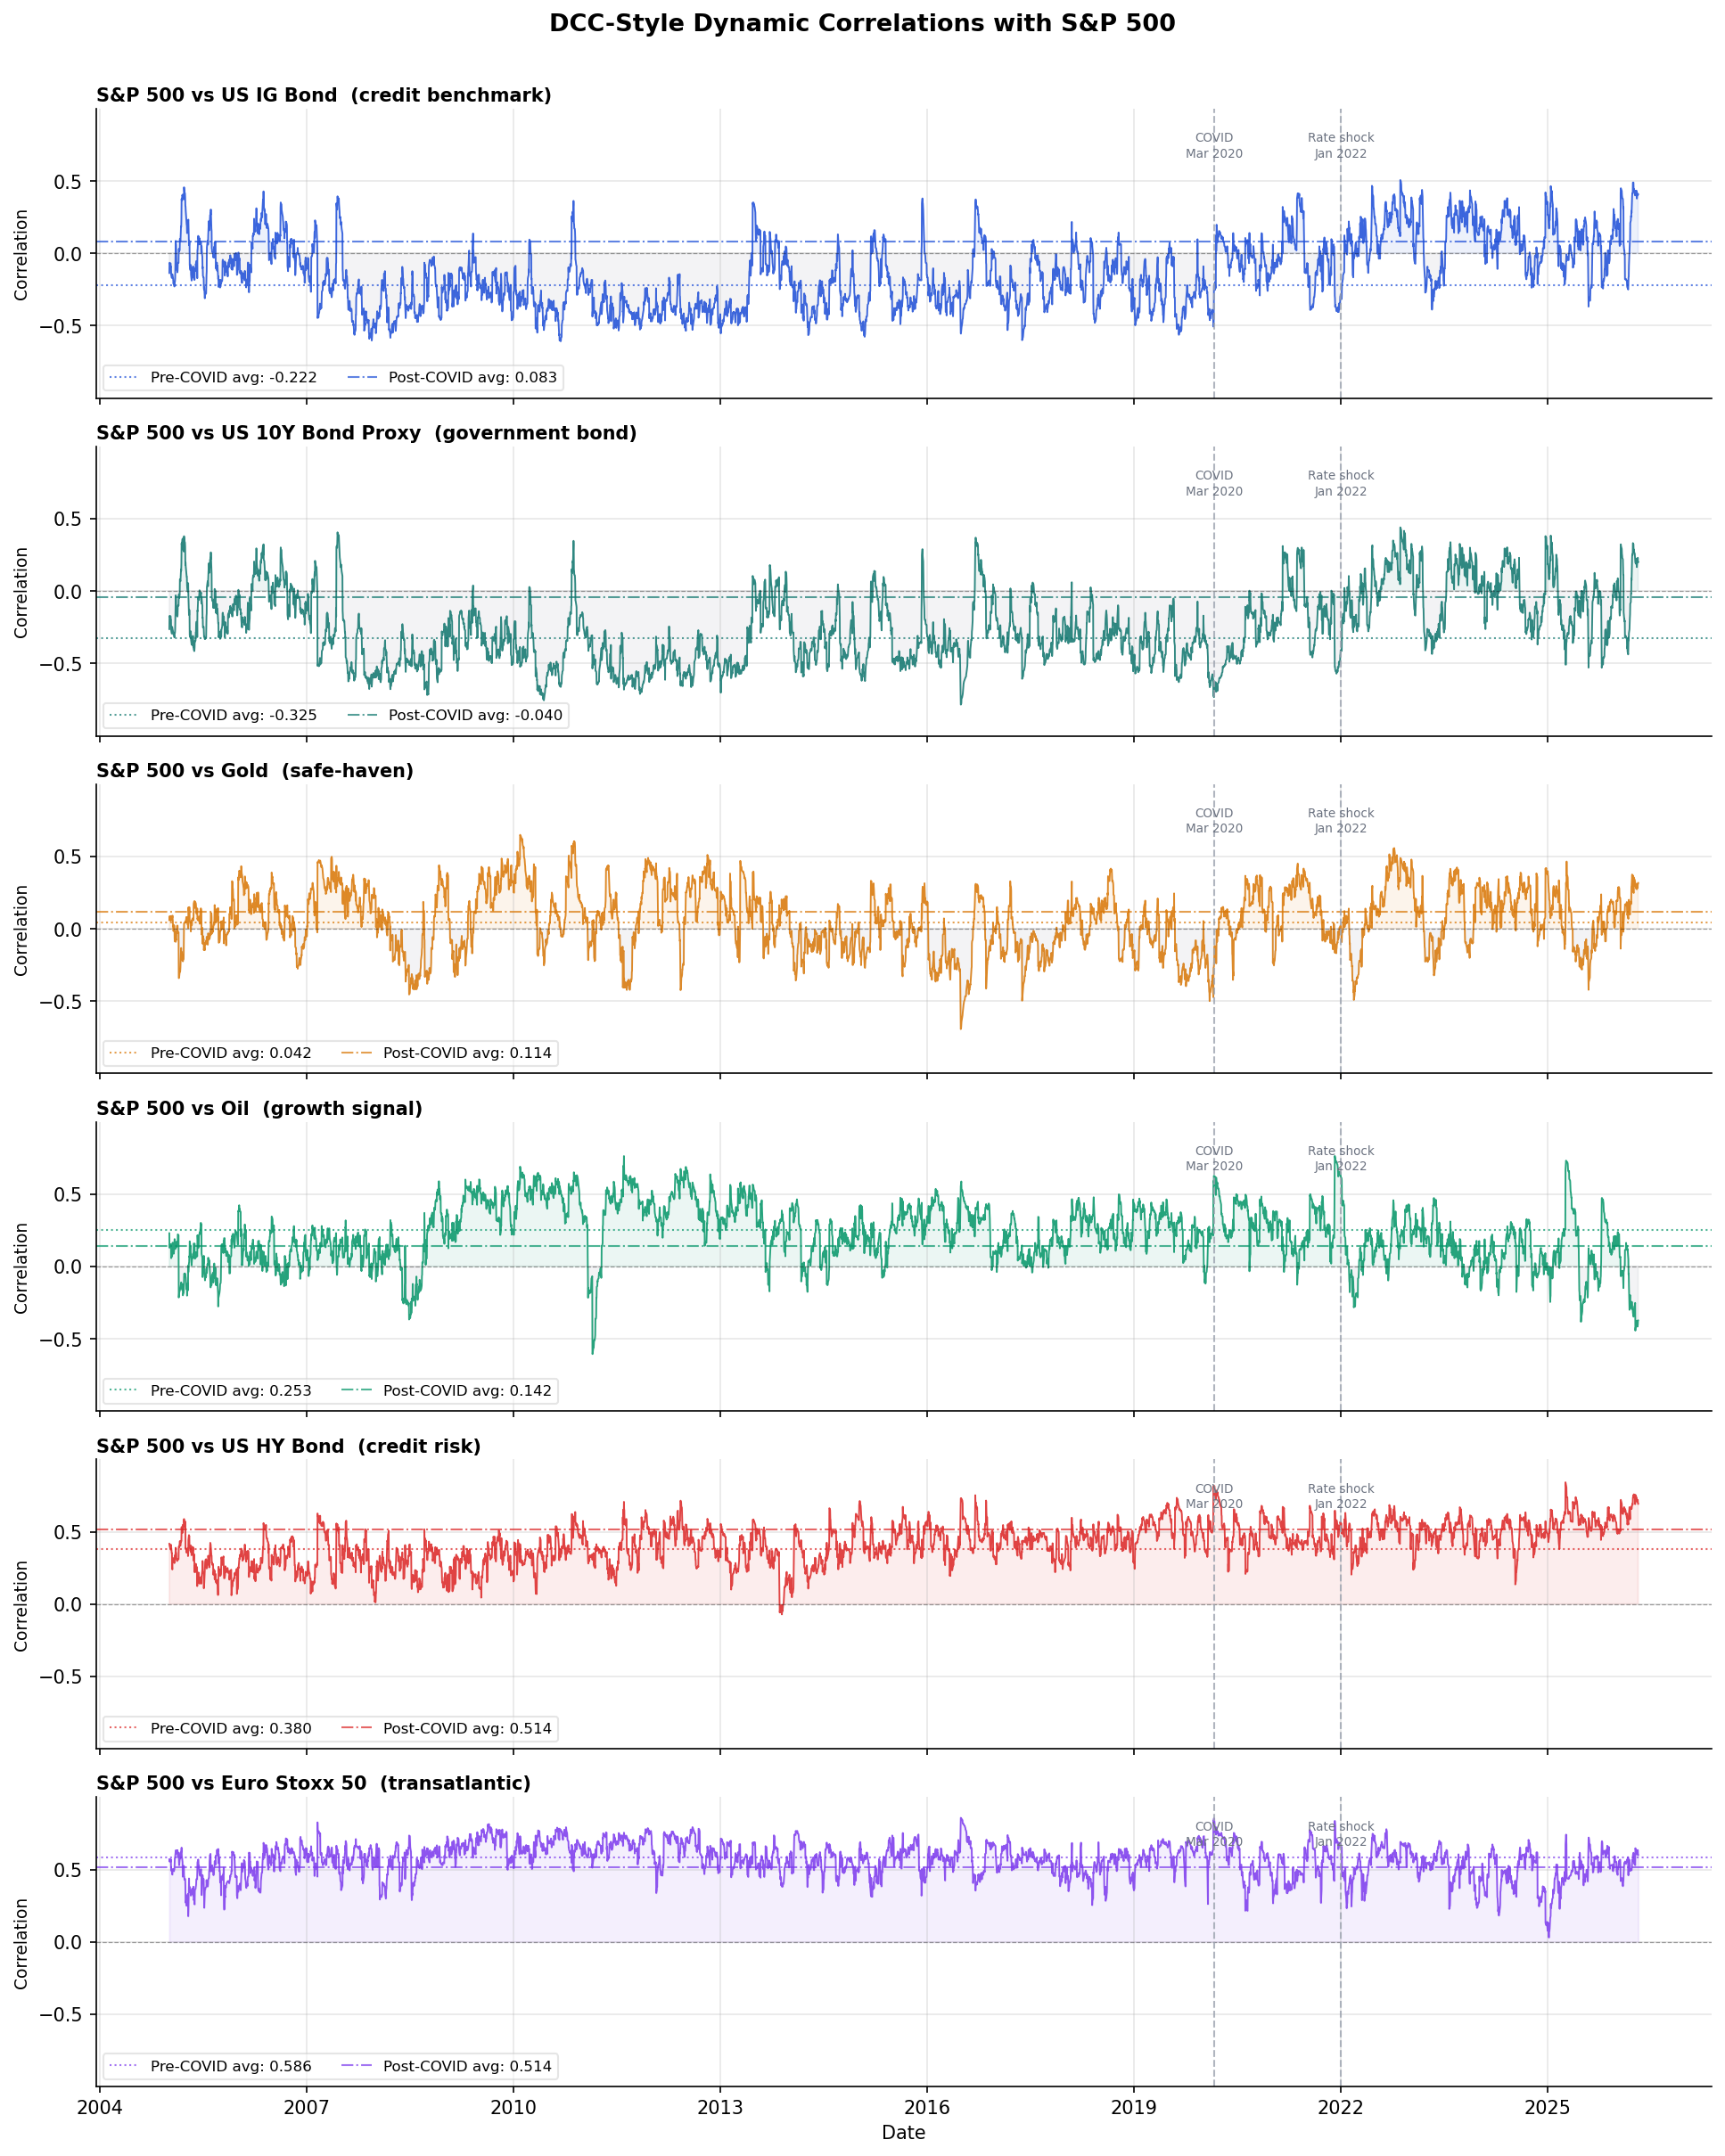

-------------------------------------------------------
  DCC Correlation — Pre vs Post COVID Averages
-------------------------------------------------------
  Pair                     Pre-COVID  Post-COVID    Change
  ----------------------  ----------  ----------  --------
  sp500_us_ig                -0.2221      0.0834   +0.3055
  sp500_us10y_proxy          -0.3251     -0.0399   +0.2852
  sp500_gold                  0.0419      0.1145   +0.0726
  sp500_oil                   0.2533      0.1419   -0.1114
  sp500_us_hy                 0.3804      0.5144   +0.1340
  sp500_euro50                0.5860      0.5141   -0.0719


In [17]:
PAIR_LABELS_DCC = {
    "sp500_us_ig"       : "S&P 500 vs US IG Bond  (credit benchmark)",
    "sp500_us10y_proxy" : "S&P 500 vs US 10Y Bond Proxy  (government bond)",
    "sp500_gold"        : "S&P 500 vs Gold  (safe-haven)",
    "sp500_oil"         : "S&P 500 vs Oil  (growth signal)",
    "sp500_us_hy"       : "S&P 500 vs US HY Bond  (credit risk)",
    "sp500_euro50"      : "S&P 500 vs Euro Stoxx 50  (transatlantic)",
}

COLORS_DCC = {
    "sp500_us_ig"       : "#1D4ED8",
    "sp500_us10y_proxy" : "#0F766E",
    "sp500_gold"        : "#D97706",
    "sp500_oil"         : "#059669",
    "sp500_us_hy"       : "#DC2626",
    "sp500_euro50"      : "#7C3AED",
}

BREAK_DATES_DCC = {
    "COVID\nMar 2020"   : "2020-03-01",
    "Rate shock\nJan 2022" : "2022-01-01",
}

fig, axes = plt.subplots(len(PAIR_LABELS_DCC), 1, figsize=(13, 16), sharex=True)
fig.suptitle("DCC-Style Dynamic Correlations with S&P 500",
             fontsize=13, fontweight="bold", y=1.005)

for ax, (pair_name, label) in zip(axes, PAIR_LABELS_DCC.items()):
    series    = dcc_corr[pair_name]
    color     = COLORS_DCC[pair_name]
    pre_mean  = dcc_corr[pair_name].loc[:PRE_END].mean()
    post_mean = dcc_corr[pair_name].loc[POST_START:].mean()

    ax.plot(series.index, series, color=color, linewidth=0.9, alpha=0.85)
    ax.fill_between(series.index, series, 0,
                    where=series >= 0, color=color,    alpha=0.08)
    ax.fill_between(series.index, series, 0,
                    where=series <  0, color="#6B7280", alpha=0.08)

    ax.axhline(0,         color="black", linewidth=0.6, linestyle="--", alpha=0.35)
    ax.axhline(pre_mean,  color=color,   linewidth=1.0, linestyle=":",  alpha=0.7,
               label=f"Pre-COVID avg: {pre_mean:.3f}")
    ax.axhline(post_mean, color=color,   linewidth=1.0, linestyle="-.", alpha=0.7,
               label=f"Post-COVID avg: {post_mean:.3f}")

    for break_label, date in BREAK_DATES_DCC.items():
        ax.axvline(pd.Timestamp(date), color="#9CA3AF",
                   linewidth=1.0, linestyle="--", alpha=0.8)
        ax.text(pd.Timestamp(date), 0.92, break_label,
                fontsize=6.5, color="#6B7280", ha="center", va="top",
                transform=ax.get_xaxis_transform(), linespacing=1.3)

    ax.set_ylabel("Correlation", fontsize=9)
    ax.set_ylim(-1.0, 1.0)
    ax.set_yticks([-0.5, 0, 0.5])
    ax.set_title(label, fontsize=10, fontweight="bold", loc="left", pad=4)
    ax.legend(fontsize=8, loc="lower left", framealpha=0.5, ncol=2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[-1].xaxis.set_major_locator(mdates.YearLocator(3))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.setp(axes[-1].xaxis.get_majorticklabels(), rotation=0, ha="center")
axes[-1].set_xlabel("Date", fontsize=10)

plt.tight_layout()
plt.savefig(FIG_DIR / "dcc_corr_pairs.png", dpi=150, bbox_inches="tight")
plt.show()

sep = "-" * 55
print(sep)
print(f"  DCC Correlation — Pre vs Post COVID Averages")
print(sep)
print(f"  {'Pair':<22}  {'Pre-COVID':>10}  {'Post-COVID':>10}  {'Change':>8}")
print(f"  {'-'*22}  {'-'*10}  {'-'*10}  {'-'*8}")
for pair_name in PAIR_LABELS_DCC:
    pre  = dcc_corr[pair_name].loc[:PRE_END].mean()
    post = dcc_corr[pair_name].loc[POST_START:].mean()
    print(f"  {pair_name:<22}  {pre:>10.4f}  {post:>10.4f}  {post-pre:>+8.4f}")

The summary table reports the pre-COVID average, post-COVID average and the change in DCC correlation for each pair. The sign and magnitude of the change are the primary evidence for whether cross-asset diversification properties shifted after COVID.

## 18. DCC Pre/Post COVID Formal Tests

A Welch t-test is applied to each DCC correlation series to formally test whether the mean correlation shifted significantly between the pre-COVID and post-COVID subsamples. The Welch variant is used to allow for unequal variances across the two periods:

$$t = \frac{\bar{\rho}_{post} - \bar{\rho}_{pre}}{\sqrt{\frac{s^2_{pre}}{n_{pre}} + \frac{s^2_{post}}{n_{post}}}}$$

In [18]:
test_records = []

for pair_name in dcc_corr.columns:
    pre_series  = dcc_corr[pair_name].loc[:PRE_END].dropna()
    post_series = dcc_corr[pair_name].loc[POST_START:].dropna()

    if len(pre_series) < 10 or len(post_series) < 10:
        test_records.append({
            "pair": pair_name, "pre_mean": np.nan, "post_mean": np.nan,
            "delta": np.nan, "t_stat": np.nan, "p_value": np.nan,
            "note": "insufficient observations",
        })
        continue

    t_stat, p_val = ttest_ind(post_series, pre_series, equal_var=False)
    test_records.append({
        "pair"     : pair_name,
        "pre_mean" : round(pre_series.mean(),                    4),
        "post_mean": round(post_series.mean(),                   4),
        "delta"    : round(post_series.mean() - pre_series.mean(), 4),
        "t_stat"   : round(t_stat,                               4),
        "p_value"  : round(p_val,                                6),
        "note"     : "",
    })

dcc_tests = pd.DataFrame(test_records).set_index("pair")
dcc_tests.to_csv(TAB_DIR / "dcc_pre_post_tests.csv")

def fmt_pval(p):
    if pd.isna(p):  return "n/a"
    if p < 0.0001:  return "< 0.0001"
    if p < 0.001:   return "< 0.001"
    if p < 0.01:    return "< 0.01"
    if p < 0.05:    return "< 0.05"
    return f"{p:.4f}"

display_tests = dcc_tests.copy()
display_tests["significant"] = dcc_tests["p_value"].apply(
    lambda p: "Yes" if (not pd.isna(p) and p < 0.05) else "No"
)
display_tests["p_value"] = dcc_tests["p_value"].apply(fmt_pval)

sep = "-" * 55
print(sep)
print("  DCC Correlation — Pre vs Post COVID t-test")
print(f"  Test : Welch t-test (unequal variance)")
print(f"  Pre  : up to {PRE_END}   Post: from {POST_START}")
print(f"  H0   : mean pre-COVID correlation = mean post-COVID correlation")
print(sep)
print(display_tests.to_string())

-------------------------------------------------------
  DCC Correlation — Pre vs Post COVID t-test
  Test : Welch t-test (unequal variance)
  Pre  : up to 2019-12-31   Post: from 2021-01-01
  H0   : mean pre-COVID correlation = mean post-COVID correlation
-------------------------------------------------------
                   pre_mean  post_mean   delta   t_stat   p_value note significant
pair                                                                              
sp500_us_ig         -0.2221     0.0834  0.3055  49.0722  < 0.0001              Yes
sp500_us10y_proxy   -0.3251    -0.0399  0.2852  41.8228  < 0.0001              Yes
sp500_gold           0.0419     0.1145  0.0726  11.2731  < 0.0001              Yes
sp500_oil            0.2533     0.1419 -0.1114 -17.6492  < 0.0001              Yes
sp500_us_hy          0.3804     0.5144  0.1340  39.1397  < 0.0001              Yes
sp500_euro50         0.5860     0.5141 -0.0719 -19.4233  < 0.0001              Yes


The table reports the pre- and post-COVID mean DCC correlation, the change in mean, the t-statistic and the p-value for each pair. A significant result indicates that the shift in average correlation is unlikely to be due to sampling variation alone.

## 19. Structural Break Tests

A formal structural break test is applied to the primary stock-bond DCC correlation series. The DCC series is regressed on a constant and a post-break dummy variable, with Newey-West HAC standard errors to account for autocorrelation in the daily correlation series:

$$\rho_t = \alpha + \beta \cdot \mathbf{1}_{t \geq t^*} + \varepsilon_t$$

The test is run for two candidate break dates — March 2020 (COVID crash) and January 2022 (start of the rate-hiking cycle). The null hypothesis is $\beta = 0$, i.e. no level shift at the chosen date. The same test is applied to the US IG bond series as a secondary comparison.

In [19]:
SERIES_LABELS = {
    "sp500_us10y_proxy": "S&P 500 vs US 10Y bond proxy (government-bond benchmark)",
    "sp500_us_ig"      : "S&P 500 vs US IG bond (credit comparison)",
}

PRIMARY_SB_PAIR    = "sp500_us10y_proxy" if "sp500_us10y_proxy" in dcc_corr.columns else "sp500_us_ig"
PRIMARY_SB_LABEL   = SERIES_LABELS.get(PRIMARY_SB_PAIR, PRIMARY_SB_PAIR)
COMPARISON_SB_PAIR = "sp500_us_ig" if PRIMARY_SB_PAIR != "sp500_us_ig" \
                     and "sp500_us_ig" in dcc_corr.columns else None

sb_corr  = dcc_corr[PRIMARY_SB_PAIR].dropna()
HAC_LAGS = 20

def break_test_hac(series, break_date, nlags=20):
    break_date = pd.Timestamp(break_date)
    df          = pd.DataFrame({"corr": series})
    df["dummy"] = (df.index >= break_date).astype(int)

    X       = sm.add_constant(df["dummy"])
    y       = df["corr"]
    ols_fit = sm.OLS(y, X).fit()
    hac_fit = ols_fit.get_robustcov_results(
        cov_type="HAC", maxlags=nlags, use_correction=True,
    )

    ci = hac_fit.conf_int()
    return {
        "pair"        : PRIMARY_SB_PAIR,
        "break_date"  : break_date.date(),
        "pre_mean"    : series.loc[series.index <  break_date].mean(),
        "post_mean"   : series.loc[series.index >= break_date].mean(),
        "beta_coef"   : hac_fit.params[1],
        "t_stat"      : hac_fit.tvalues[1],
        "p_value"     : hac_fit.pvalues[1],
        "ci_95_lower" : ci[1, 0],
        "ci_95_upper" : ci[1, 1],
        "n_obs"       : len(series),
        "n_pre"       : (series.index <  break_date).sum(),
        "n_post"      : (series.index >= break_date).sum(),
        "hac_lags"    : nlags,
    }

break_dates  = ["2020-03-01", "2022-01-01"]
results      = [break_test_hac(sb_corr, d, nlags=HAC_LAGS) for d in break_dates]
break_results = pd.DataFrame(results).set_index("break_date")
break_results.to_csv(TAB_DIR / "break_results.csv")

break_results_compare = pd.DataFrame()
if COMPARISON_SB_PAIR is not None:
    comp_series = dcc_corr[COMPARISON_SB_PAIR].dropna()
    comp_rows   = []
    for d in break_dates:
        row         = break_test_hac(comp_series, d, nlags=HAC_LAGS)
        row["pair"] = COMPARISON_SB_PAIR
        comp_rows.append(row)
    break_results_compare = pd.DataFrame(comp_rows).set_index("break_date")
    break_results_compare.to_csv(TAB_DIR / "break_results_comparison.csv")

def fmt_pval(p):
    if pd.isna(p):  return "n/a"
    if p < 0.0001:  return "< 0.0001"
    if p < 0.001:   return "< 0.001"
    if p < 0.01:    return "< 0.01"
    if p < 0.05:    return "< 0.05"
    return f"{p:.4f}"

display_br = break_results.copy()
for col in ["pre_mean", "post_mean", "beta_coef", "t_stat", "ci_95_lower", "ci_95_upper"]:
    display_br[col] = display_br[col].round(4)
display_br["p_value"]     = break_results["p_value"].apply(fmt_pval)
display_br["significant"] = break_results["p_value"].apply(
    lambda p: "Yes" if (not pd.isna(p) and p < 0.05) else "No"
)

sep = "-" * 60
print(sep)
print("  Structural Break Tests — Primary Stock-Bond DCC Series")
print(f"  Series : {PRIMARY_SB_LABEL}")
print(f"  Model  : rho_t = alpha + beta * D_t + epsilon_t")
print(f"  SE     : Newey-West HAC, maxlags = {HAC_LAGS}")
print(f"  H0     : beta = 0 (no structural break at this date)")
print(sep)
print(display_br[[
    "pair", "pre_mean", "post_mean", "beta_coef",
    "t_stat", "p_value", "ci_95_lower", "ci_95_upper", "significant"
]].to_string())
print(sep)
for break_date, row in break_results.iterrows():
    sig       = "significant"     if row["p_value"] < 0.05 else "not significant"
    direction = "increased"       if row["beta_coef"] > 0  else "decreased"
    print(f"  Break {break_date}: beta = {row['beta_coef']:.4f} "
          f"({sig} at 5%, p = {fmt_pval(row['p_value'])})")
    print(f"  Correlation {direction} by {abs(row['beta_coef']):.4f}  "
          f"| Pre: {row['pre_mean']:.4f}  Post: {row['post_mean']:.4f}")

if not break_results_compare.empty:
    comp_display = break_results_compare.copy()
    for col in ["pre_mean", "post_mean", "beta_coef", "t_stat", "ci_95_lower", "ci_95_upper"]:
        comp_display[col] = comp_display[col].round(4)
    comp_display["p_value"]     = break_results_compare["p_value"].apply(fmt_pval)
    comp_display["significant"] = break_results_compare["p_value"].apply(
        lambda p: "Yes" if (not pd.isna(p) and p < 0.05) else "No"
    )
    print(sep)
    print("  Secondary Comparison — Stock-Credit DCC Series")
    print(f"  Series : {SERIES_LABELS.get(COMPARISON_SB_PAIR, COMPARISON_SB_PAIR)}")
    print(sep)
    print(comp_display[[
        "pair", "pre_mean", "post_mean", "beta_coef",
        "t_stat", "p_value", "significant"
    ]].to_string())

------------------------------------------------------------
  Structural Break Tests — Primary Stock-Bond DCC Series
  Series : S&P 500 vs US 10Y bond proxy (government-bond benchmark)
  Model  : rho_t = alpha + beta * D_t + epsilon_t
  SE     : Newey-West HAC, maxlags = 20
  H0     : beta = 0 (no structural break at this date)
------------------------------------------------------------
                         pair  pre_mean  post_mean  beta_coef   t_stat   p_value  ci_95_lower  ci_95_upper significant
break_date                                                                                                            
2020-03-01  sp500_us10y_proxy   -0.3271    -0.0830     0.2440   8.6168  < 0.0001       0.1885       0.2995         Yes
2022-01-01  sp500_us10y_proxy   -0.3169    -0.0194     0.2974  10.5247  < 0.0001       0.2420       0.3528         Yes
------------------------------------------------------------
  Break 2020-03-01: beta = 0.2440 (significant at 5%, p = < 0.0001)
  C

The table reports the estimated break coefficient $\beta$, HAC t-statistic, p-value and 95% confidence interval for each break date. A significant $\beta$ confirms a statistically meaningful shift in the stock-bond correlation at that date.

## 20. Markov-Switching Regime Model

A two-state Markov-switching regression is estimated on the weekly stock-bond DCC correlation series to identify whether the data supports distinct high- and low-correlation regimes beyond the structural break evidence. The model allows both the mean and variance to switch across regimes. If the model converges, the smoothed regime probabilities are used to colour the DCC series by regime. If it does not converge, a fallback chart with simple positive/negative shading is produced instead.


Weekly stock-bond DCC series: 1,112 observations
  2005-01-07 to 2026-04-24
Markov-switching model converged.
                        Markov Switching Model Results                        
Dep. Variable:      sp500_us10y_proxy   No. Observations:                 1112
Model:               MarkovRegression   Log Likelihood                 409.775
Date:                Sun, 24 May 2026   AIC                           -807.551
Time:                        23:54:20   BIC                           -777.467
Sample:                    01-07-2005   HQIC                          -796.176
                         - 04-24-2026                                         
Covariance Type:               approx                                         
                             Regime 0 parameters                              
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0280

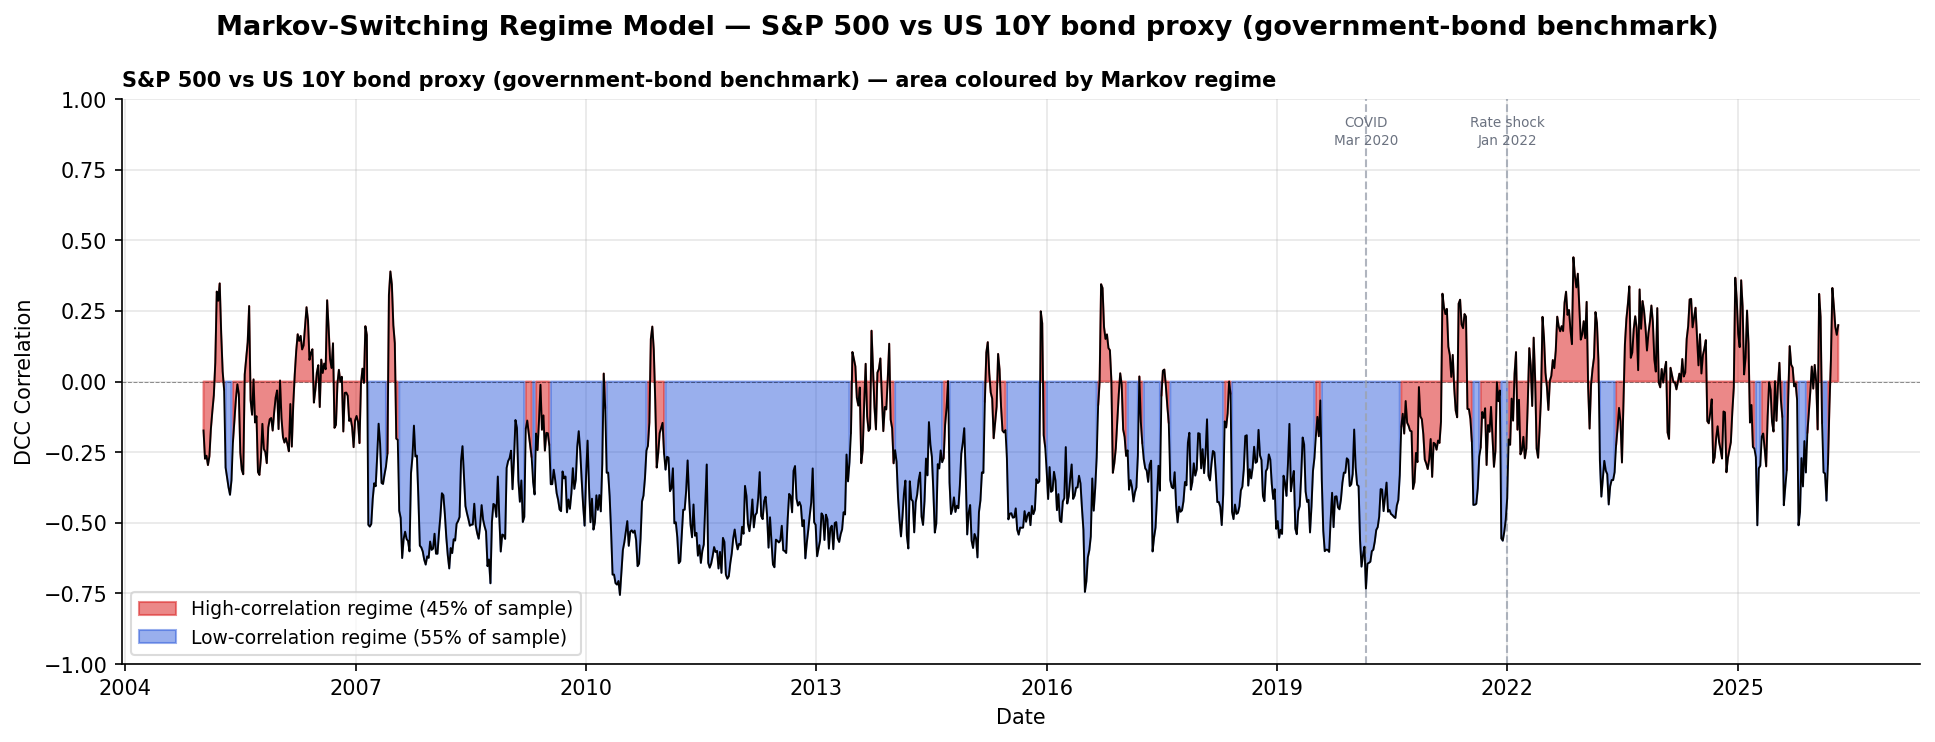

  High-correlation regime : 44.7% of sample
  Low-correlation regime  : 55.3% of sample


In [20]:
series_pair  = PRIMARY_SB_PAIR if "PRIMARY_SB_PAIR" in globals() else (
               "sp500_us10y_proxy" if "sp500_us10y_proxy" in dcc_corr.columns else "sp500_us_ig")
series_label = SERIES_LABELS.get(series_pair, series_pair) if "SERIES_LABELS" in globals() else series_pair

sb_corr_daily  = dcc_corr[series_pair].dropna()
sb_corr_weekly = sb_corr_daily.resample("W-FRI").last().dropna()

print(f"Weekly stock-bond DCC series: {len(sb_corr_weekly):,} observations")
print(f"  {sb_corr_weekly.index[0].date()} to {sb_corr_weekly.index[-1].date()}")

ms_converged = False
ms_result    = None

try:
    ms_model  = MarkovRegression(
        sb_corr_weekly, k_regimes=2, trend="c", switching_variance=True,
    )
    ms_result = ms_model.fit(
        search_reps=20, search_iter=20, disp=False, maxiter=200,
    )

    smoothed  = ms_result.smoothed_marginal_probabilities
    probs_ok  = (np.isfinite(smoothed.values).all() and
                 np.allclose(smoothed.sum(axis=1), 1.0, atol=0.01))

    if probs_ok:
        ms_converged = True
        print("Markov-switching model converged.")
        print(ms_result.summary())
    else:
        print("Markov-switching: probabilities invalid — falling back to structural-break evidence.")

except Exception as e:
    print(f"Markov-switching failed: {e}")

BREAK_CONFIG = {
    "COVID\nMar 2020"      : "2020-03-01",
    "Rate shock\nJan 2022" : "2022-01-01",
}

def add_break_lines(ax):
    for label, date in BREAK_CONFIG.items():
        ax.axvline(pd.Timestamp(date), color="#9CA3AF",
                   linewidth=1.0, linestyle="--", alpha=0.8)
        ax.text(pd.Timestamp(date), 0.97, label, fontsize=6.5,
                color="#6B7280", ha="center", va="top",
                transform=ax.get_xaxis_transform(), linespacing=1.3)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

def set_xaxis(ax):
    ax.xaxis.set_major_locator(mdates.YearLocator(3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=0)

if ms_converged:
    smoothed         = ms_result.smoothed_marginal_probabilities
    means            = [ms_result.params[f"const[{k}]"] for k in range(2)]
    high_risk_regime = int(np.argmax(means))
    prob_high        = smoothed.iloc[:, high_risk_regime]
    regime_indicator = (prob_high >= 0.5).astype(int)
    pct_high         = regime_indicator.mean() * 100

    fig, ax = plt.subplots(figsize=(13, 5))
    fig.suptitle(f"Markov-Switching Regime Model — {series_label}",
                 fontsize=13, fontweight="bold")

    ax.plot(sb_corr_weekly.index, sb_corr_weekly,
            color="black", linewidth=0.9, zorder=3)
    ax.fill_between(sb_corr_weekly.index, sb_corr_weekly, 0,
                    where=(regime_indicator == 1).values,
                    color="#DC2626", alpha=0.55, zorder=2,
                    label=f"High-correlation regime ({pct_high:.0f}% of sample)")
    ax.fill_between(sb_corr_weekly.index, sb_corr_weekly, 0,
                    where=(regime_indicator == 0).values,
                    color="#1D4ED8", alpha=0.45, zorder=2,
                    label=f"Low-correlation regime ({100-pct_high:.0f}% of sample)")

    ax.axhline(0, color="black", linewidth=0.5, linestyle="--", alpha=0.4)
    ax.set_ylabel("DCC Correlation", fontsize=10)
    ax.set_ylim(-1.0, 1.0)
    ax.set_xlabel("Date", fontsize=10)
    ax.set_title(f"{series_label} — area coloured by Markov regime",
                 fontsize=10, fontweight="bold", loc="left")
    ax.legend(fontsize=9, loc="lower left", framealpha=0.7)
    add_break_lines(ax)
    set_xaxis(ax)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "regime_states.png", dpi=150, bbox_inches="tight")
    plt.show()

    print(f"  High-correlation regime : {pct_high:.1f}% of sample")
    print(f"  Low-correlation regime  : {100-pct_high:.1f}% of sample")

else:
    fig, ax = plt.subplots(figsize=(13, 4))
    ax.plot(sb_corr_weekly.index, sb_corr_weekly,
            color="#1D4ED8", linewidth=0.9)
    ax.fill_between(sb_corr_weekly.index, sb_corr_weekly, 0,
                    where=sb_corr_weekly >= 0,
                    color="#DC2626", alpha=0.25, label="Positive correlation")
    ax.fill_between(sb_corr_weekly.index, sb_corr_weekly, 0,
                    where=sb_corr_weekly <  0,
                    color="#1D4ED8", alpha=0.15, label="Negative correlation")
    ax.axhline(0, color="black", linewidth=0.6, linestyle="--", alpha=0.4)
    ax.set_ylabel("DCC Correlation", fontsize=10)
    ax.set_ylim(-1.0, 1.0)
    ax.set_xlabel("Date", fontsize=10)
    ax.set_title(f"{series_label} — Markov-switching did not converge",
                 fontsize=10, fontweight="bold")
    ax.legend(fontsize=8, loc="lower left")
    add_break_lines(ax)
    set_xaxis(ax)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "regime_states.png", dpi=150, bbox_inches="tight")
    plt.show()

If the model converged, the chart shows the DCC series coloured by the most probable regime at each date, together with the fraction of the sample spent in each regime. Failure to converge is itself informative — it suggests the post-COVID dynamics are better described as a structural break than as a stable cyclical regime switch.

## 21. Extended History Check

The Markov-switching regime analysis is extended to the full available history by reconstructing a rolling stock-government-bond correlation proxy directly from the raw price data. This allows the regime structure to be placed in a longer historical context, covering multiple economic cycles before the 2005 start of the main sample.

Stock column    : S&P500
Gov yield column: US T 10-year Yield
Full proxy series: 1990-04-06 to 2026-04-24


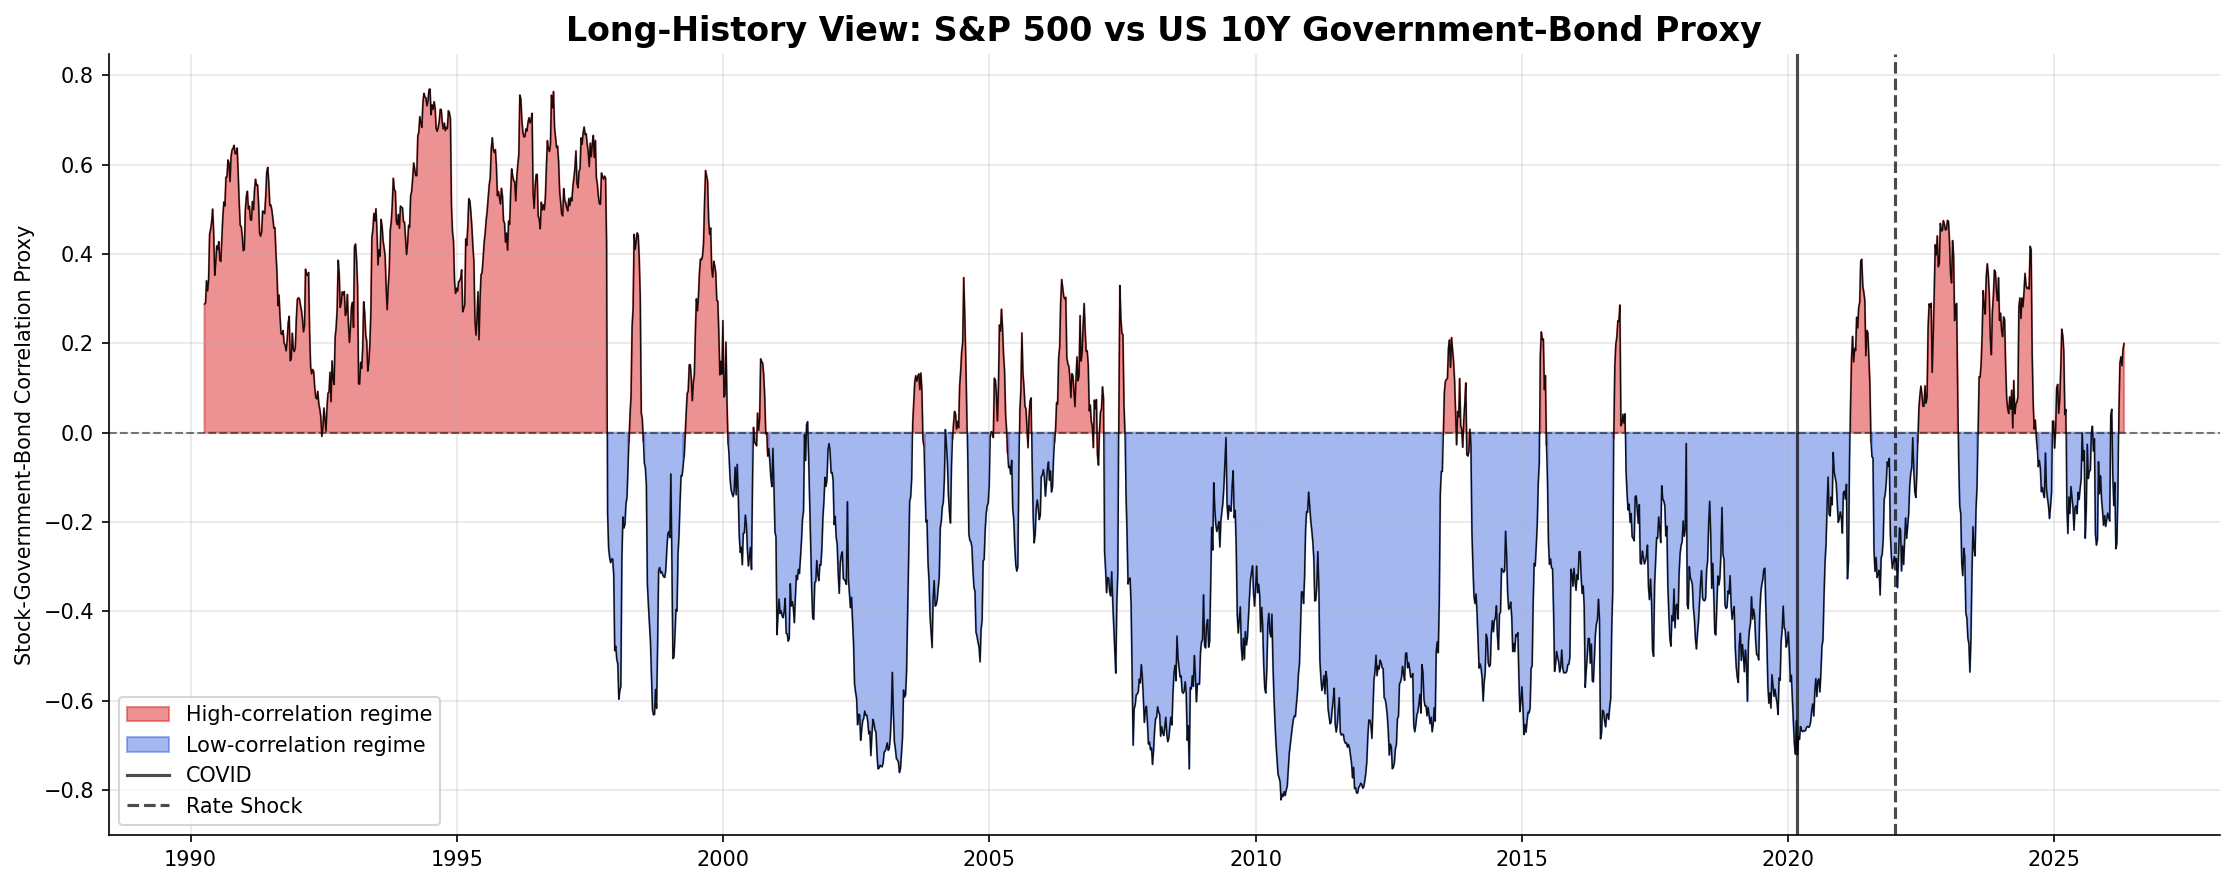

In [21]:
try:
    raw_df  = pd.read_excel("Data.xlsx", index_col=0, parse_dates=True)

    sp_col  = [c for c in raw_df.columns
               if "sp" in c.lower() or "500" in c.lower()][0]
    gov_col = [c for c in raw_df.columns
               if "us t 10" in c.lower()
               or ("us" in c.lower() and "10" in c.lower()
                   and "yield" in c.lower())][0]

    print(f"Stock column    : {sp_col}")
    print(f"Gov yield column: {gov_col}")

    full_proxy               = pd.DataFrame(index=raw_df.index)
    full_proxy["stock_ret"]  = np.log(raw_df[sp_col]).diff()
    full_proxy["gov_bond_proxy"] = -8.5 * raw_df[gov_col].diff() / 100.0
    full_proxy               = full_proxy.dropna()

    full_sb_proxy    = (full_proxy["stock_ret"]
                        .rolling(window=60)
                        .corr(full_proxy["gov_bond_proxy"])
                        .dropna())
    sb_weekly_full   = full_sb_proxy.resample("W-FRI").last().dropna()

    print(f"Full proxy series: {sb_weekly_full.index[0].date()} "
          f"to {sb_weekly_full.index[-1].date()}")

except Exception as e:
    print(f"Could not build long-history government-bond proxy: {e}")
    raise

try:
    ms_model  = MarkovRegression(sb_weekly_full, k_regimes=2,
                                  trend="c", switching_variance=True)
    ms_result = ms_model.fit(search_reps=50, disp=False)

    smoothed         = ms_result.smoothed_marginal_probabilities
    means            = [ms_result.params[f"const[{k}]"] for k in range(2)]
    high_corr_regime = int(np.argmax(means))
    regime_indicator = (smoothed.iloc[:, high_corr_regime] >= 0.5).astype(int)

    fig, ax = plt.subplots(figsize=(15, 6), dpi=150)

    ax.plot(sb_weekly_full.index, sb_weekly_full,
            color="black", linewidth=0.7, alpha=0.9)
    ax.fill_between(sb_weekly_full.index, sb_weekly_full, 0,
                    where=(regime_indicator == 1),
                    color="#DC2626", alpha=0.5, label="High-correlation regime")
    ax.fill_between(sb_weekly_full.index, sb_weekly_full, 0,
                    where=(regime_indicator == 0),
                    color="#1D4ED8", alpha=0.4, label="Low-correlation regime")
    ax.axhline(0, color="black", linewidth=1, linestyle="--", alpha=0.5)

    ax.axvline(pd.Timestamp("2020-03-01"), color="black",
               alpha=0.7, label="COVID")
    ax.axvline(pd.Timestamp("2022-01-01"), color="black",
               linestyle="--", alpha=0.7, label="Rate Shock")

    ax.set_title("Long-History View: S&P 500 vs US 10Y Government-Bond Proxy",
                 fontsize=16, fontweight="bold")
    ax.set_ylabel("Stock-Government-Bond Correlation Proxy")
    ax.xaxis.set_major_locator(mdates.YearLocator(5))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.legend(loc="lower left")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.savefig(FIG_DIR / "regime_states_1990_2026.png", dpi=300,
                bbox_inches="tight")
    plt.show()

except Exception as e:
    print(f"Markov model failed on full-history proxy: {e}")

The chart shows the full-history rolling correlation coloured by Markov regime. The two vertical lines mark the COVID crash and the start of the rate-hiking cycle. This extended view helps assess whether the post-2022 shift to positive stock-bond correlation is historically unusual or has precedent in earlier periods.

## 22. Regime Zoom — 2019 to Present

The Markov regime chart is zoomed in on the period from 2019 onwards to give a closer view of the dynamics around the COVID crash, the inflation and rate-hiking cycle, the Fed pivot and the most recent geopolitical episode. Pre- and post-COVID average correlations are shown as reference lines. Key events are marked with annotated vertical lines.

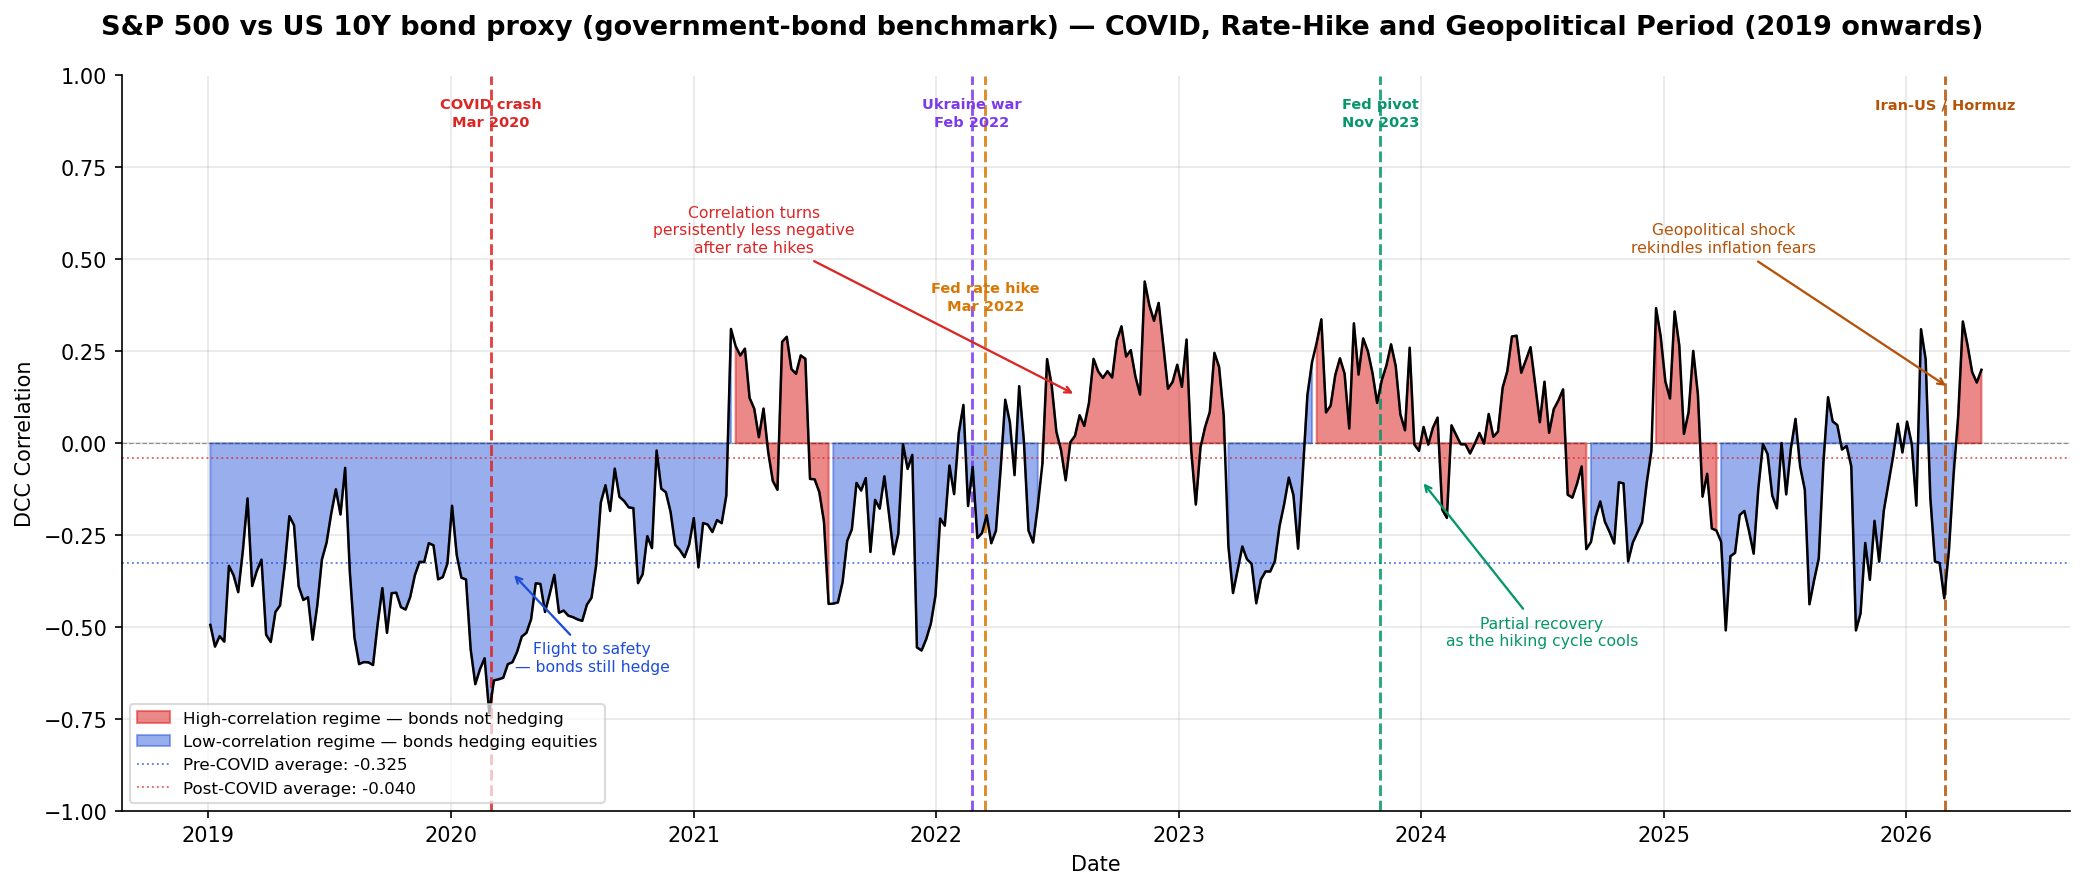

In [22]:
if ms_converged:
    zoom_start = "2019-01-01"
    sb_zoom    = sb_corr_weekly.loc[zoom_start:]
    ri_zoom    = regime_indicator.loc[zoom_start:]

    pre_avg  = dcc_corr[series_pair].loc[:PRE_END].mean()
    post_avg = dcc_corr[series_pair].loc[POST_START:].mean()

    events = {
        "COVID crash\nMar 2020"    : ("2020-03-01", "#DC2626", 0.97),
        "Ukraine war\nFeb 2022"    : ("2022-02-24", "#7C3AED", 0.97),
        "Fed rate hike\nMar 2022"  : ("2022-03-16", "#D97706", 0.72),
        "Fed pivot\nNov 2023"      : ("2023-11-01", "#059669", 0.97),
        "Iran-US / Hormuz"         : ("2026-02-28", "#B45309", 0.97),
    }

    fig, ax = plt.subplots(figsize=(14, 6))
    fig.suptitle(
        f"{series_label} — COVID, Rate-Hike and Geopolitical Period (2019 onwards)",
        fontsize=13, fontweight="bold"
    )

    ax.plot(sb_zoom.index, sb_zoom, color="black", linewidth=1.2, zorder=3)
    ax.fill_between(sb_zoom.index, sb_zoom, 0,
                    where=(ri_zoom == 1).values,
                    color="#DC2626", alpha=0.55, zorder=2,
                    label="High-correlation regime — bonds not hedging")
    ax.fill_between(sb_zoom.index, sb_zoom, 0,
                    where=(ri_zoom == 0).values,
                    color="#1D4ED8", alpha=0.45, zorder=2,
                    label="Low-correlation regime — bonds hedging equities")

    ax.axhline(0,        color="black",   linewidth=0.6, linestyle="--", alpha=0.4)
    ax.axhline(pre_avg,  color="#1D4ED8", linewidth=0.9, linestyle=":",  alpha=0.7,
               label=f"Pre-COVID average: {pre_avg:.3f}")
    ax.axhline(post_avg, color="#DC2626", linewidth=0.9, linestyle=":",  alpha=0.7,
               label=f"Post-COVID average: {post_avg:.3f}")

    for label, (date, color, label_y) in events.items():
        ts = pd.Timestamp(date)
        if ts >= pd.Timestamp(zoom_start):
            ax.axvline(ts, color=color, linewidth=1.4, linestyle="--", alpha=0.85)
            ax.text(ts, label_y, label, fontsize=7, color=color,
                    ha="center", va="top",
                    transform=ax.get_xaxis_transform(),
                    linespacing=1.4, fontweight="bold")

    ax.annotate(
        "Flight to safety\n— bonds still hedge",
        xy=(pd.Timestamp("2020-04-01"), -0.35),
        xytext=(pd.Timestamp("2020-08-01"), -0.62),
        fontsize=7.5, color="#1D4ED8", ha="center",
        arrowprops=dict(arrowstyle="->", color="#1D4ED8", lw=1.1),
    )
    ax.annotate(
        "Correlation turns\npersistently less negative\nafter rate hikes",
        xy=(pd.Timestamp("2022-08-01"), 0.13),
        xytext=(pd.Timestamp("2021-04-01"), 0.52),
        fontsize=7.5, color="#DC2626", ha="center",
        arrowprops=dict(arrowstyle="->", color="#DC2626", lw=1.1),
    )
    ax.annotate(
        "Partial recovery\nas the hiking cycle cools",
        xy=(pd.Timestamp("2024-01-01"), -0.10),
        xytext=(pd.Timestamp("2024-07-01"), -0.55),
        fontsize=7.5, color="#059669", ha="center",
        arrowprops=dict(arrowstyle="->", color="#059669", lw=1.1),
    )
    ax.annotate(
        "Geopolitical shock\nrekindles inflation fears",
        xy=(pd.Timestamp("2026-03-07"), 0.15),
        xytext=(pd.Timestamp("2025-04-01"), 0.52),
        fontsize=7.5, color="#B45309", ha="center",
        arrowprops=dict(arrowstyle="->", color="#B45309", lw=1.1),
    )

    ax.set_ylabel("DCC Correlation", fontsize=10)
    ax.set_xlabel("Date", fontsize=10)
    ax.set_ylim(-1.0, 1.0)
    ax.legend(fontsize=8, loc="lower left", framealpha=0.7)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.xaxis.set_major_locator(mdates.YearLocator(1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

    plt.tight_layout()
    plt.savefig(FIG_DIR / "regime_states_zoom.png", dpi=150, bbox_inches="tight")
    plt.show()


The chart traces the evolution of the stock-bond correlation through each macro episode. The regime shading and annotations together provide the clearest visual summary of when and why the correlation structure changed over this period.

## 23. 60/40 Portfolio — Government Bond Benchmark

A simple 60/40 portfolio is constructed using 60% S&P 500 and 40% US 10Y government-bond return proxy to translate the correlation findings into portfolio language. Rolling 63-day volatility and drawdown are computed over the full sample to assess how portfolio risk evolved across the pre-COVID and post-COVID periods.

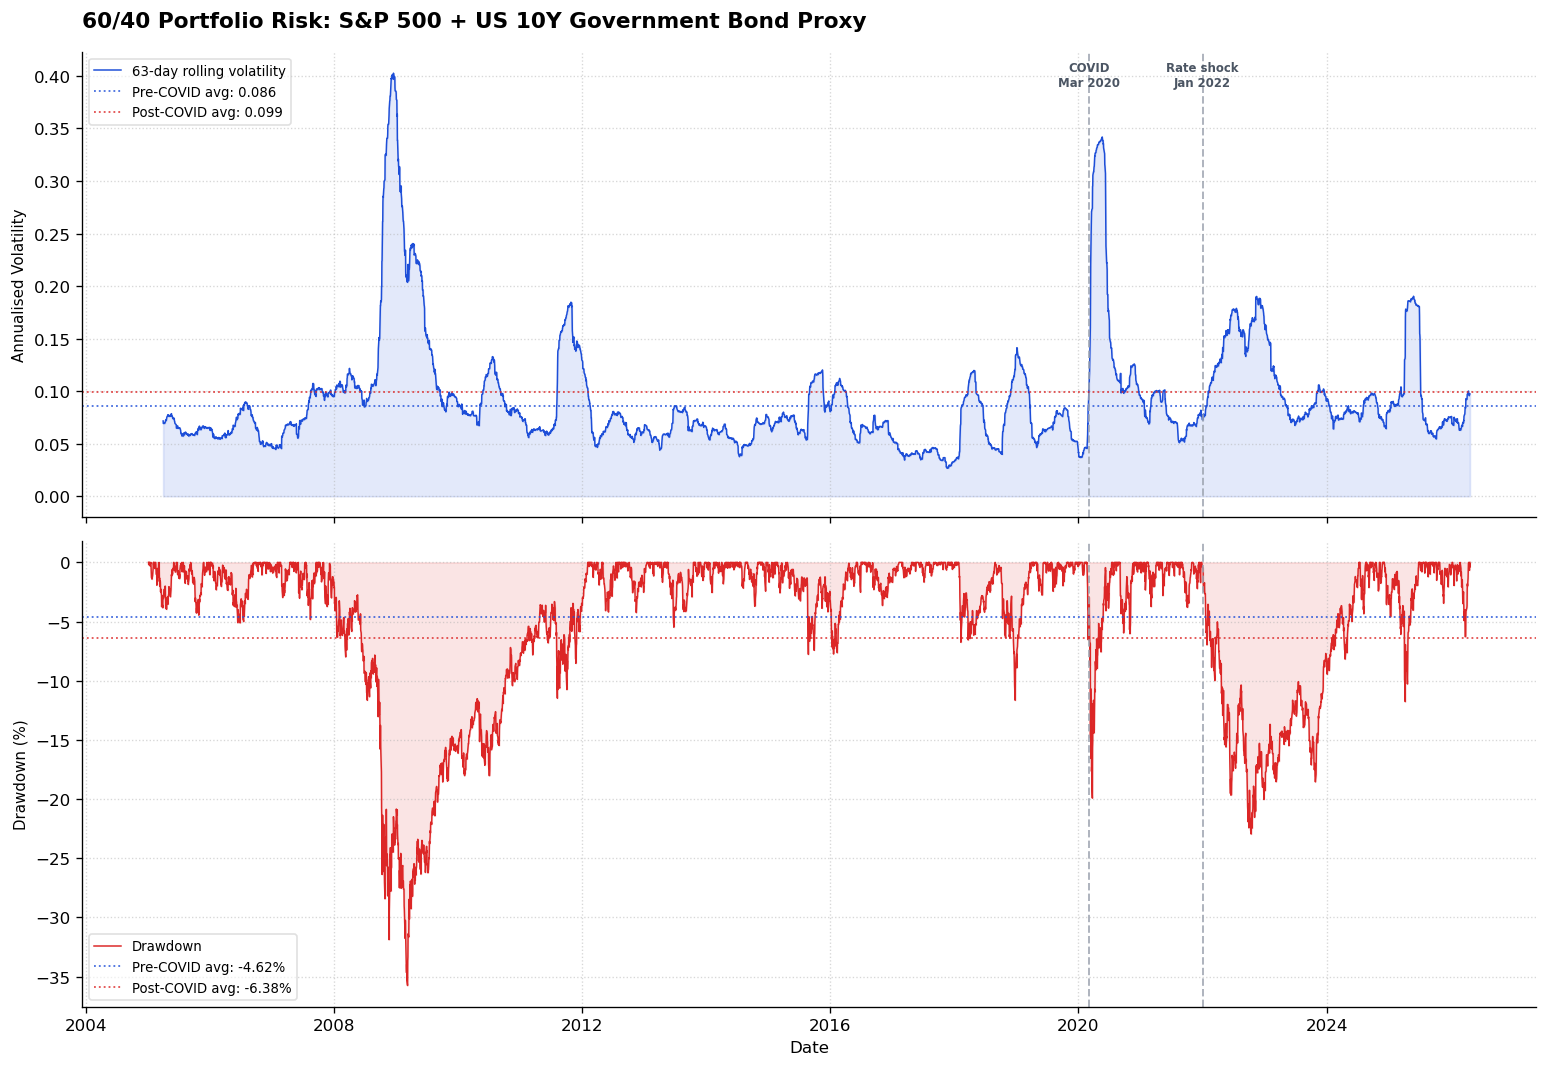

--------------------------------------------------
  60/40 Portfolio Summary — Pre vs Post COVID
--------------------------------------------------
                    Pre-COVID  Post-COVID
Observations        3911.0000   1386.0000
Ann. Return            0.0432      0.0495
Ann. RF Proxy          0.0292      0.0335
Ann. Excess Return     0.0141      0.0160
Ann. Volatility        0.0998      0.1062
Sharpe Ratio           0.1408      0.1505
Max Drawdown          -0.3575     -0.2296
Avg Rolling Vol        0.0858      0.0991


In [23]:
df_analysis = returns_model.loc["2005-01-01":].copy()
df_analysis["rf_proxy_daily"] = risk_free_daily.reindex(df_analysis.index).ffill()

df_analysis["r_6040"]      = (0.60 * df_analysis["sp500"] +
                               0.40 * df_analysis["us10y_bond_proxy"])
df_analysis["excess_6040"] = df_analysis["r_6040"] - df_analysis["rf_proxy_daily"]

ROLL = 63
df_analysis["roll_vol"]  = df_analysis["r_6040"].rolling(ROLL).std() * np.sqrt(252)
df_analysis["wealth"]    = np.exp(df_analysis["r_6040"].cumsum())
df_analysis["drawdown"]  = df_analysis["wealth"] / df_analysis["wealth"].cummax() - 1

def get_regime_stats(df_slice, label):
    r      = df_slice["r_6040"].dropna()
    rf     = df_slice.loc[r.index, "rf_proxy_daily"].ffill()
    excess = r - rf

    local_wealth = np.exp(r.cumsum())
    local_dd     = local_wealth / local_wealth.cummax() - 1

    ann_ret        = r.mean() * 252
    ann_rf         = rf.mean() * 252
    ann_excess_ret = excess.mean() * 252
    ann_vol        = r.std() * np.sqrt(252)
    sharpe         = ann_excess_ret / ann_vol if ann_vol > 0 else np.nan

    return {
        "Observations"      : len(r),
        "Ann. Return"       : round(ann_ret,        4),
        "Ann. RF Proxy"     : round(ann_rf,          4),
        "Ann. Excess Return": round(ann_excess_ret,  4),
        "Ann. Volatility"   : round(ann_vol,         4),
        "Sharpe Ratio"      : round(sharpe,          4),
        "Max Drawdown"      : round(local_dd.min(),  4),
        "Avg Rolling Vol"   : round(df_slice["roll_vol"].mean(), 4),
    }

pre_stats  = get_regime_stats(df_analysis.loc[:PRE_END],    "Pre-COVID")
post_stats = get_regime_stats(df_analysis.loc[POST_START:], "Post-COVID")
port_6040_stats = pd.DataFrame({"Pre-COVID": pre_stats, "Post-COVID": post_stats})

BREAK_LINES = {
    "COVID\nMar 2020"    : "2020-03-01",
    "Rate shock\nJan 2022" : "2022-01-01",
}

pre_vol_avg  = df_analysis.loc[:PRE_END,    "roll_vol"].mean()
post_vol_avg = df_analysis.loc[POST_START:, "roll_vol"].mean()
pre_dd_avg   = df_analysis.loc[:PRE_END,    "drawdown"].mean() * 100
post_dd_avg  = df_analysis.loc[POST_START:, "drawdown"].mean() * 100

fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True, dpi=120)
ax1, ax2  = axes

ax1.plot(df_analysis.index, df_analysis["roll_vol"],
         color="#1D4ED8", linewidth=0.9, label="63-day rolling volatility")
ax1.fill_between(df_analysis.index, df_analysis["roll_vol"], 0,
                 color="#1D4ED8", alpha=0.12)
ax1.axhline(pre_vol_avg,  color="#1D4ED8", linewidth=1.1, linestyle=":", alpha=0.8,
            label=f"Pre-COVID avg: {pre_vol_avg:.3f}")
ax1.axhline(post_vol_avg, color="#DC2626", linewidth=1.1, linestyle=":", alpha=0.8,
            label=f"Post-COVID avg: {post_vol_avg:.3f}")
ax1.set_ylabel("Annualised Volatility", fontsize=9)
ax1.set_title("60/40 Portfolio Risk: S&P 500 + US 10Y Government Bond Proxy",
              fontsize=13, fontweight="bold", loc="left", pad=15)
ax1.legend(fontsize=8, loc="upper left", framealpha=0.6)

ax2.plot(df_analysis.index, df_analysis["drawdown"] * 100,
         color="#DC2626", linewidth=0.9, label="Drawdown")
ax2.fill_between(df_analysis.index, df_analysis["drawdown"] * 100, 0,
                 color="#DC2626", alpha=0.12)
ax2.axhline(pre_dd_avg,  color="#1D4ED8", linewidth=1.1, linestyle=":", alpha=0.8,
            label=f"Pre-COVID avg: {pre_dd_avg:.2f}%")
ax2.axhline(post_dd_avg, color="#DC2626", linewidth=1.1, linestyle=":", alpha=0.8,
            label=f"Post-COVID avg: {post_dd_avg:.2f}%")
ax2.set_ylabel("Drawdown (%)", fontsize=9)
ax2.legend(fontsize=8, loc="lower left", framealpha=0.6)

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(True, linestyle=":", alpha=0.5)
    for label, date in BREAK_LINES.items():
        ax.axvline(pd.Timestamp(date), color="#9CA3AF",
                   linewidth=1.2, linestyle="--", alpha=0.8)

for label, date in BREAK_LINES.items():
    ax1.text(pd.Timestamp(date), ax1.get_ylim()[1] * 0.98, label,
             fontsize=7, color="#4B5563", ha="center", va="top", fontweight="bold")

ax2.xaxis.set_major_locator(mdates.YearLocator(4))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax2.set_xlabel("Date", fontsize=10)

plt.tight_layout()
plt.savefig(FIG_DIR / "portfolio_6040_risk_styled.png", dpi=300, bbox_inches="tight")
plt.show()

port_6040_stats.to_csv(TAB_DIR / "portfolio_6040_summary_vertical.csv")

sep = "-" * 50
print(sep)
print("  60/40 Portfolio Summary — Pre vs Post COVID")
print(sep)
print(port_6040_stats.to_string())

The top panel shows annualised rolling volatility and the bottom panel shows the drawdown series. The summary table reports annualised return, volatility, Sharpe ratio and maximum drawdown for each subperiod. An increase in volatility or drawdown in the post-COVID period is consistent with a weakening of the government-bond hedge.

## 24. Equal Risk Contribution Portfolio

The ERC portfolio assigns weights so that each asset contributes equally to total portfolio variance at each monthly rebalancing date. The weights are obtained by minimising:

$$\min_w \sum_{i=1}^{N}\left(\frac{w_i (Hw)_i}{w'Hw} - \frac{1}{N}\right)^2 \qquad \text{s.t.} \quad \sum_i w_i = 1, \quad w_i \geq 0$$

where $H$ is the DCC conditional covariance matrix. Weights are computed monthly using lagged covariance matrices to avoid look-ahead bias. The full-sample, pre-COVID and post-COVID performance statistics are reported together with the evolution of group-level weights and DCC-implied dynamic betas.

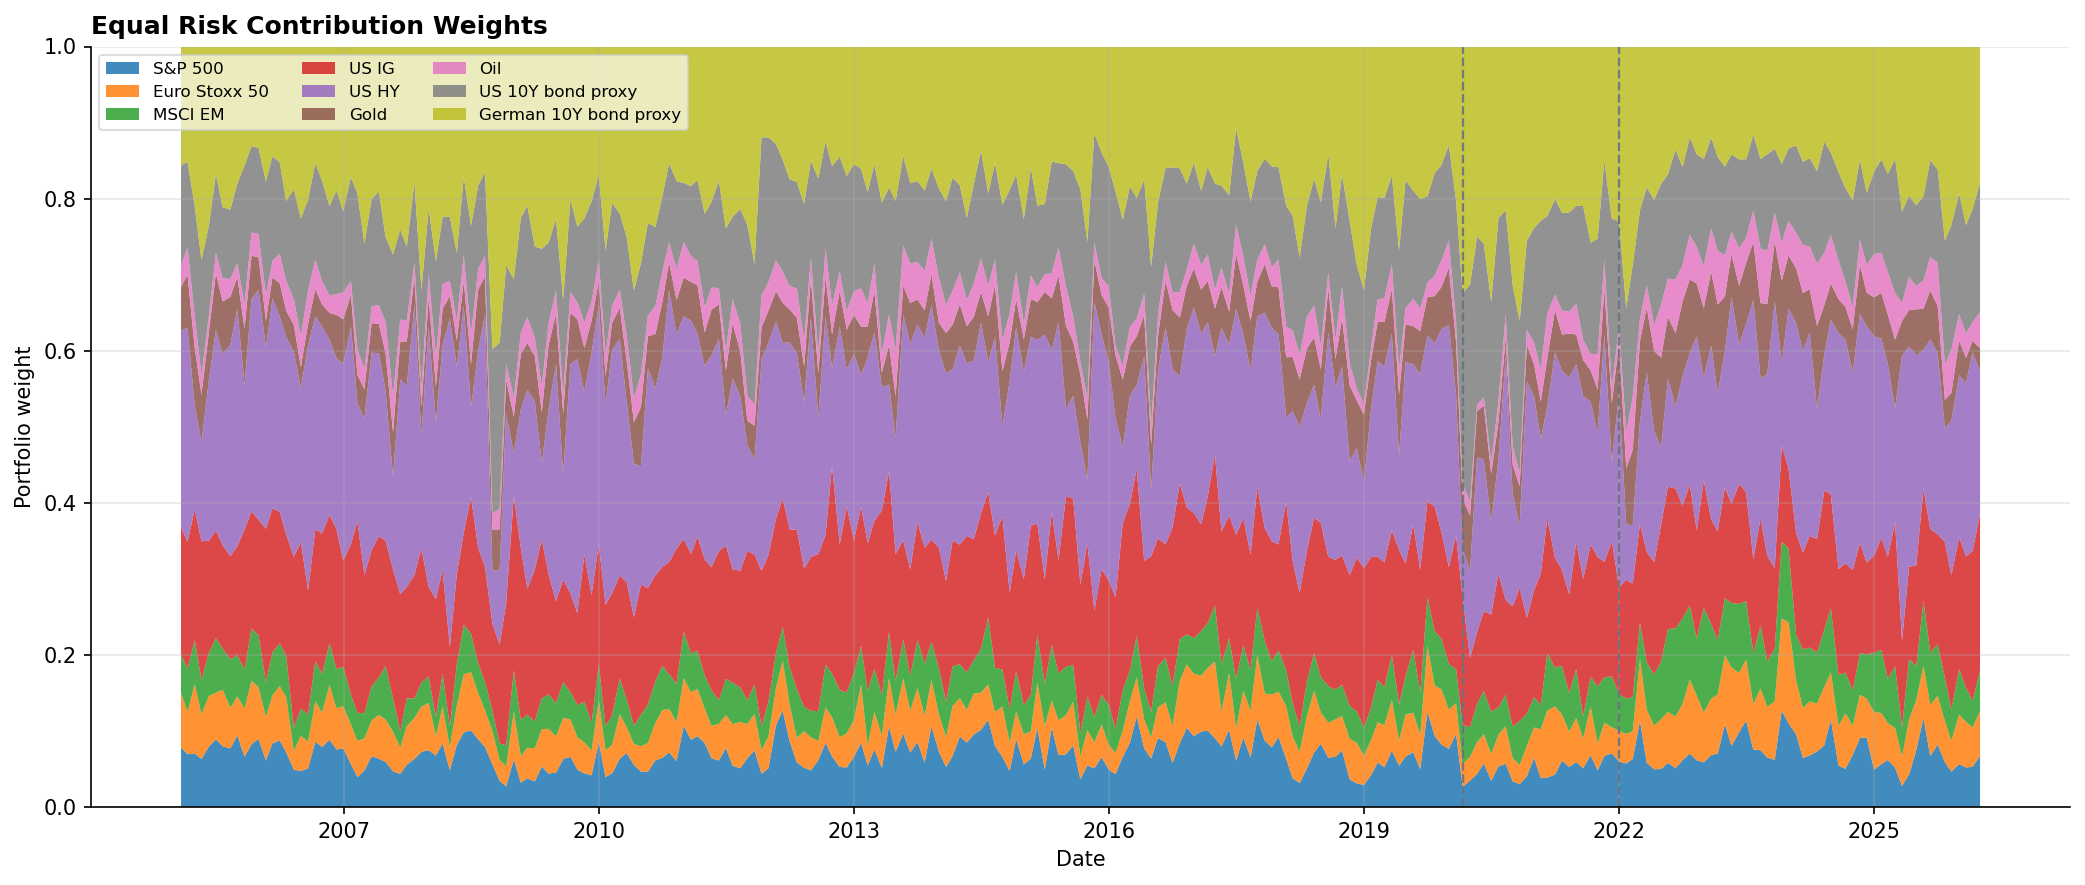

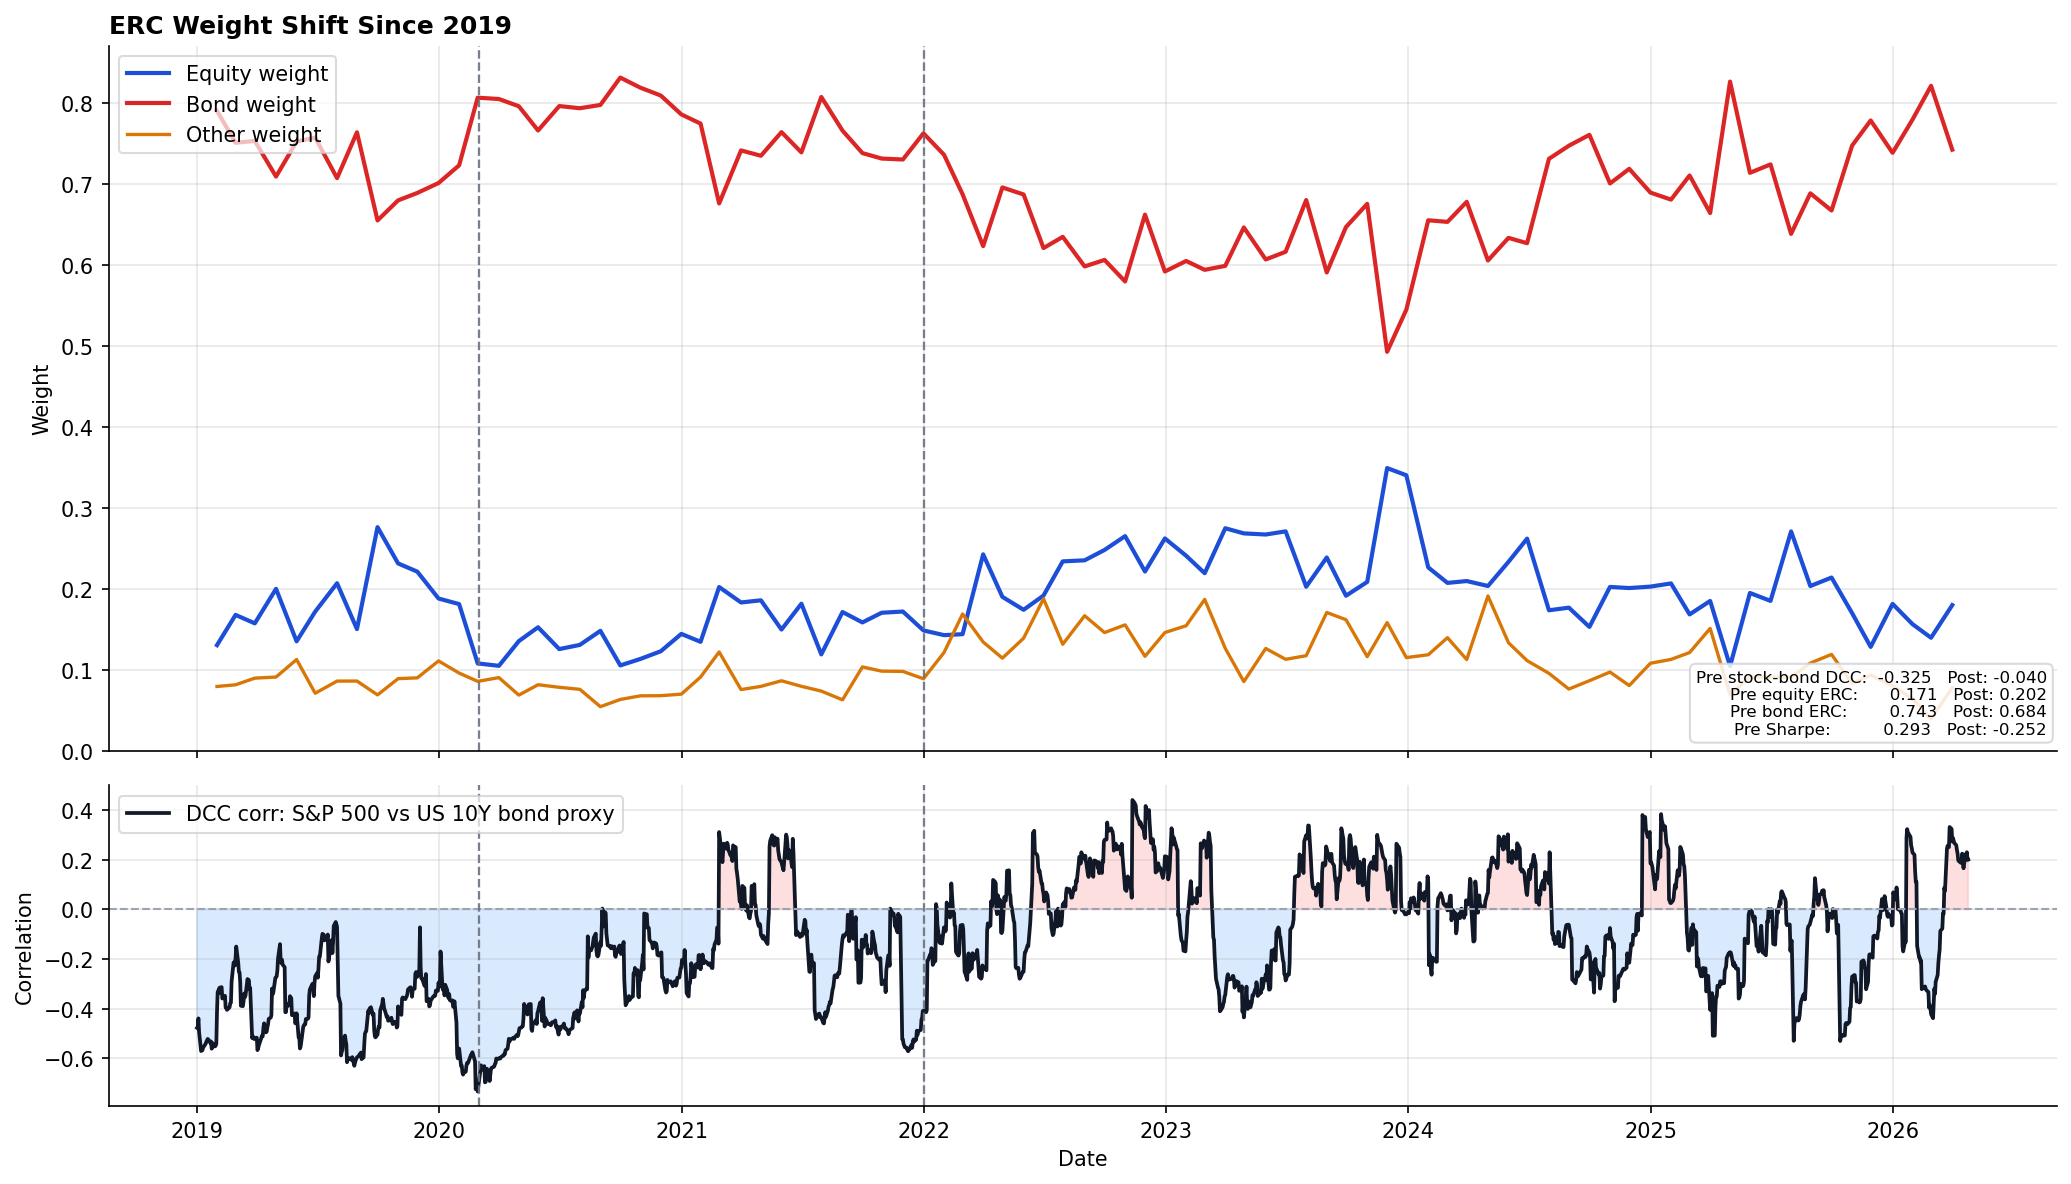

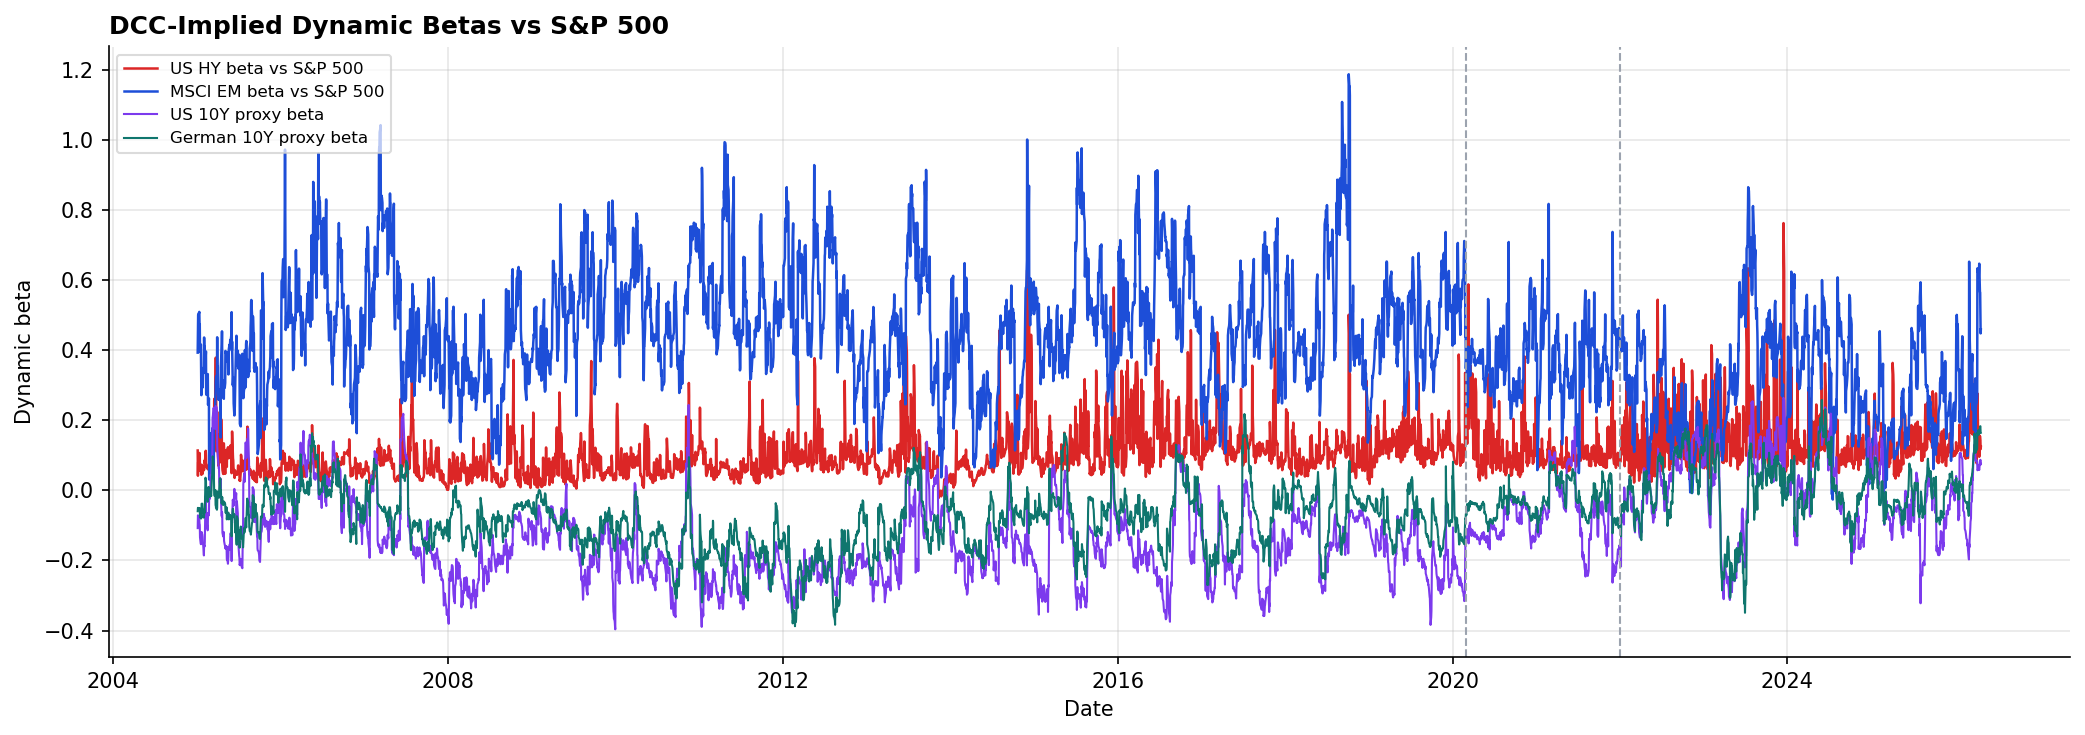

-------------------------------------------------------
  ERC Portfolio — Performance Summary
-------------------------------------------------------
             mean_daily  ann_return  ann_rf_proxy  ann_excess_return   ann_vol  sharpe_rf_proxy  max_drawdown  n_obs
period                                                                                                              
full_sample    0.000140    0.035320      0.029239           0.006081  0.047809         0.127194     -0.227395   5518
pre_covid      0.000164    0.041217      0.029067           0.012150  0.041442         0.293182     -0.227395   3872
post_covid     0.000077    0.019496      0.033539          -0.014043  0.055836        -0.251505     -0.200891   1386
-------------------------------------------------------
  Monthly ERC weights computed: 255


In [24]:
ERC_ASSETS = MODEL_ASSETS.copy()

asset_labels = {
    "sp500"            : "S&P 500",
    "euro50"           : "Euro Stoxx 50",
    "msci_em"          : "MSCI EM",
    "us_ig"            : "US IG",
    "us_hy"            : "US HY",
    "gold"             : "Gold",
    "oil"              : "Oil",
    "us10y_bond_proxy" : "US 10Y bond proxy",
    "de10y_bond_proxy" : "German 10Y bond proxy",
}

equity_cols = ["sp500", "euro50", "msci_em"]
bond_cols   = ["us_ig", "us_hy", "us10y_bond_proxy", "de10y_bond_proxy"]
other_cols  = ["gold", "oil"]


def regularize_covariance(H):
    H              = np.asarray(H, dtype=float)
    H              = 0.5 * (H + H.T)
    eigvals, eigvecs = np.linalg.eigh(H)
    eigvals        = np.clip(eigvals, 1e-12, None)
    H_reg          = eigvecs @ np.diag(eigvals) @ eigvecs.T
    return 0.5 * (H_reg + H_reg.T)


def erc_objective(w, H):
    port_var = float(w @ H @ w)
    if port_var <= 0 or not np.isfinite(port_var):
        return 1e9
    mrc     = H @ w
    rc_frac = (w * mrc) / port_var
    target  = np.full(len(w), 1.0 / len(w))
    return float(np.sum((rc_frac - target) ** 2))


def risk_contribution_fraction(w, H):
    port_var = float(w @ H @ w)
    return (w * (H @ w)) / port_var


def inverse_vol_start(H):
    vols = np.sqrt(np.clip(np.diag(H), 1e-12, None))
    w    = 1.0 / vols
    return w / w.sum()


def solve_erc(H, previous_weights=None):
    H        = regularize_covariance(H)
    n_assets = H.shape[0]
    bounds   = [(1e-8, 1.0) for _ in range(n_assets)]
    cons     = {"type": "eq", "fun": lambda w: np.sum(w) - 1.0}

    starts = []
    if previous_weights is not None and np.isfinite(previous_weights).all():
        starts.append(np.asarray(previous_weights, dtype=float))
    starts.append(np.full(n_assets, 1.0 / n_assets))
    starts.append(inverse_vol_start(H))

    best = None
    for w0 in starts:
        w0  = np.clip(w0, 1e-8, 1.0)
        w0  = w0 / w0.sum()
        res = minimize(erc_objective, w0, args=(H,), method="SLSQP",
                       bounds=bounds, constraints=cons,
                       options={"maxiter": 1000, "ftol": 1e-12})
        w   = np.clip(res.x if res.success else w0, 1e-8, 1.0)
        w   = w / w.sum()
        candidate = {
            "weights"         : w,
            "objective"       : erc_objective(w, H),
            "max_abs_rc_error": float(np.max(np.abs(
                                    risk_contribution_fraction(w, H) - 1.0 / n_assets))),
            "success"         : bool(res.success),
            "message"         : str(res.message),
        }
        if best is None or candidate["objective"] < best["objective"]:
            best = candidate
    return best


h_idx      = pd.DatetimeIndex(sorted(H_t.keys()))
month_ends = []
for period_end in pd.date_range(h_idx.min(), h_idx.max(), freq="ME"):
    valid = [d for d in h_idx if d <= period_end]
    if valid:
        month_ends.append(valid[-1])
month_ends = pd.DatetimeIndex(sorted(set(month_ends)))

erc_records  = []
diag_records = []
prev_w       = None

for date in month_ends:
    H_df   = H_t[date]
    H      = H_df.loc[ERC_ASSETS, ERC_ASSETS].values \
             if hasattr(H_df, "loc") else np.asarray(H_df)
    result = solve_erc(H, previous_weights=prev_w)
    w      = result["weights"]
    prev_w = w

    weight_row = {"date": date}
    weight_row.update({asset: float(w[i]) for i, asset in enumerate(ERC_ASSETS)})
    erc_records.append(weight_row)
    diag_records.append({
        "date"             : date,
        "objective"        : result["objective"],
        "max_abs_rc_error" : result["max_abs_rc_error"],
        "success"          : result["success"],
        "message"          : result["message"],
    })

erc_weights      = pd.DataFrame(erc_records).set_index("date").sort_index()
erc_weights.index = pd.to_datetime(erc_weights.index)
erc_diagnostics  = pd.DataFrame(diag_records).set_index("date").sort_index()
erc_diagnostics.index = pd.to_datetime(erc_diagnostics.index)

erc_weights.to_csv(TAB_DIR     / "erc_weights.csv")
erc_diagnostics.to_csv(TAB_DIR / "erc_diagnostics.csv")

erc_weights_lagged = erc_weights.shift(1)
weights_daily      = erc_weights_lagged.reindex(returns_model.index).ffill()
weights_daily      = weights_daily.loc[:, ERC_ASSETS]

aligned_returns = returns_model[ERC_ASSETS].copy()
valid_mask      = (weights_daily.notna().all(axis=1) &
                   aligned_returns.notna().all(axis=1))
weights_daily   = weights_daily.loc[valid_mask]
aligned_returns = aligned_returns.loc[valid_mask]

rf_aligned  = risk_free_daily.reindex(aligned_returns.index).ffill()
r_erc       = (weights_daily * aligned_returns).sum(axis=1)
excess_r_erc = r_erc - rf_aligned

erc_portfolio_returns = pd.DataFrame({
    "r_erc"           : r_erc,
    "rf_proxy_daily"  : rf_aligned,
    "excess_r_erc"    : excess_r_erc,
    "wealth"          : np.exp(r_erc.cumsum()),
})
erc_portfolio_returns.to_csv(TAB_DIR / "erc_portfolio_returns.csv")


def max_drawdown_from_wealth(wealth):
    return float((wealth / wealth.cummax() - 1.0).min())


def perf_stats(series, rf_series):
    series    = series.dropna()
    rf_series = rf_series.reindex(series.index).ffill()
    excess    = series - rf_series
    wealth    = np.exp(series.cumsum())
    ann_vol   = float(series.std()) * np.sqrt(252)
    ann_excess = float(excess.mean()) * 252
    return {
        "mean_daily"        : float(series.mean()),
        "ann_return"        : float(series.mean()) * 252,
        "ann_rf_proxy"      : float(rf_series.mean()) * 252,
        "ann_excess_return" : ann_excess,
        "ann_vol"           : ann_vol,
        "sharpe_rf_proxy"   : ann_excess / ann_vol if ann_vol > 0 else np.nan,
        "max_drawdown"      : max_drawdown_from_wealth(wealth),
        "n_obs"             : int(series.shape[0]),
    }


perf_windows = {
    "full_sample" : erc_portfolio_returns.index,
    "pre_covid"   : erc_portfolio_returns.loc[:PRE_END].index,
    "post_covid"  : erc_portfolio_returns.loc[POST_START:].index,
}
perf_rows = []
for label, idx in perf_windows.items():
    row = {"period": label}
    row.update(perf_stats(
        erc_portfolio_returns.loc[idx, "r_erc"],
        erc_portfolio_returns.loc[idx, "rf_proxy_daily"],
    ))
    perf_rows.append(row)

erc_perf_summary = pd.DataFrame(perf_rows).set_index("period")
erc_perf_summary.to_csv(TAB_DIR / "erc_performance_summary.csv")

erc_group_weights = pd.DataFrame(index=erc_weights.index)
erc_group_weights["equity_weight"] = erc_weights[equity_cols].sum(axis=1)
erc_group_weights["bond_weight"]   = erc_weights[bond_cols].sum(axis=1)
erc_group_weights["other_weight"]  = erc_weights[other_cols].sum(axis=1)
erc_group_weights.to_csv(TAB_DIR / "erc_group_weights.csv")

fig, ax = plt.subplots(figsize=(14, 6))
ax.stackplot(
    erc_weights.index,
    [erc_weights[col] for col in ERC_ASSETS],
    labels=[asset_labels[col] for col in ERC_ASSETS],
    alpha=0.85,
)
for event_date in ["2020-03-01", "2022-01-01"]:
    ax.axvline(pd.Timestamp(event_date), color="#6B7280",
               linestyle="--", linewidth=1.1, alpha=0.9)
ax.set_ylim(0, 1)
ax.set_ylabel("Portfolio weight")
ax.set_xlabel("Date")
ax.set_title("Equal Risk Contribution Weights", loc="left", fontweight="bold")
ax.legend(loc="upper left", ncol=3, fontsize=8, framealpha=0.65)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.xaxis.set_major_locator(mdates.YearLocator(3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout()
plt.savefig(FIG_DIR / "erc_weights.png", dpi=150, bbox_inches="tight")
plt.show()

focus_start = pd.Timestamp("2019-01-01")
erc_focus   = erc_group_weights.loc[focus_start:].copy()
corr_col    = "sp500_us10y_proxy" if "sp500_us10y_proxy" in dcc_corr.columns else "sp500_us_ig"
corr_label  = ("DCC corr: S&P 500 vs US 10Y bond proxy"
               if corr_col == "sp500_us10y_proxy"
               else "DCC corr: S&P 500 vs US IG")
corr_focus  = (dcc_corr[corr_col].loc[focus_start:].copy()
               if corr_col in dcc_corr.columns else pd.Series(dtype=float))

pre_corr_mean  = dcc_corr[corr_col].loc[:PRE_END].mean()  if corr_col in dcc_corr.columns else np.nan
post_corr_mean = dcc_corr[corr_col].loc[POST_START:].mean() if corr_col in dcc_corr.columns else np.nan
pre_eq_mean    = erc_group_weights.loc[:PRE_END,    "equity_weight"].mean()
post_eq_mean   = erc_group_weights.loc[POST_START:, "equity_weight"].mean()
pre_bond_mean  = erc_group_weights.loc[:PRE_END,    "bond_weight"].mean()
post_bond_mean = erc_group_weights.loc[POST_START:, "bond_weight"].mean()
pre_sharpe     = erc_perf_summary.loc["pre_covid",  "sharpe_rf_proxy"] \
                 if "pre_covid"  in erc_perf_summary.index else np.nan
post_sharpe    = erc_perf_summary.loc["post_covid", "sharpe_rf_proxy"] \
                 if "post_covid" in erc_perf_summary.index else np.nan

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True,
                          gridspec_kw={"height_ratios": [2.2, 1.0]})

axes[0].plot(erc_focus.index, erc_focus["equity_weight"],
             color="#1D4ED8", linewidth=2.0, label="Equity weight")
axes[0].plot(erc_focus.index, erc_focus["bond_weight"],
             color="#DC2626", linewidth=2.0, label="Bond weight")
axes[0].plot(erc_focus.index, erc_focus["other_weight"],
             color="#D97706", linewidth=1.6, label="Other weight")
for event_date in ["2020-03-01", "2022-01-01"]:
    axes[0].axvline(pd.Timestamp(event_date), color="#6B7280",
                    linestyle="--", linewidth=1.1, alpha=0.9)
axes[0].set_ylabel("Weight")
axes[0].set_title("ERC Weight Shift Since 2019", loc="left", fontweight="bold")
axes[0].legend(loc="upper left", framealpha=0.7)
axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)

textbox = (
    f"Pre stock-bond DCC:  {pre_corr_mean:.3f}   Post: {post_corr_mean:.3f}\n"
    f"Pre equity ERC:      {pre_eq_mean:.3f}   Post: {post_eq_mean:.3f}\n"
    f"Pre bond ERC:        {pre_bond_mean:.3f}   Post: {post_bond_mean:.3f}\n"
    f"Pre Sharpe:          {pre_sharpe:.3f}   Post: {post_sharpe:.3f}"
)
axes[0].text(0.995, 0.02, textbox, transform=axes[0].transAxes,
             ha="right", va="bottom", fontsize=8,
             bbox=dict(boxstyle="round,pad=0.35", facecolor="white",
                       alpha=0.85, edgecolor="#D1D5DB"))

if not corr_focus.empty:
    axes[1].plot(corr_focus.index, corr_focus, color="#111827",
                 linewidth=1.8, label=corr_label)
    axes[1].axhline(0.0, color="#9CA3AF", linestyle="--", linewidth=1.0)
    axes[1].fill_between(corr_focus.index, corr_focus, 0.0,
                         where=corr_focus >= 0, color="#FCA5A5", alpha=0.35)
    axes[1].fill_between(corr_focus.index, corr_focus, 0.0,
                         where=corr_focus <  0, color="#93C5FD", alpha=0.35)
    axes[1].legend(loc="upper left", framealpha=0.7)
for event_date in ["2020-03-01", "2022-01-01"]:
    axes[1].axvline(pd.Timestamp(event_date), color="#6B7280",
                    linestyle="--", linewidth=1.1, alpha=0.9)
axes[1].set_ylabel("Correlation")
axes[1].set_xlabel("Date")
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)
axes[1].xaxis.set_major_locator(mdates.YearLocator(1))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.tight_layout()
plt.savefig(FIG_DIR / "erc_weights_focus_2019.png", dpi=150, bbox_inches="tight")
plt.show()

sp_idx           = H_ASSETS.index("sp500")
ushy_idx         = H_ASSETS.index("us_hy")
em_idx           = H_ASSETS.index("msci_em")
us10y_proxy_idx  = H_ASSETS.index("us10y_bond_proxy") \
                   if "us10y_bond_proxy" in H_ASSETS else None
de10y_proxy_idx  = H_ASSETS.index("de10y_bond_proxy") \
                   if "de10y_bond_proxy" in H_ASSETS else None

beta_rows = []
for date in sorted(H_t.keys()):
    H_df    = H_t[date]
    H       = H_df.values if hasattr(H_df, "values") else np.asarray(H_df)
    var_sp  = H[sp_idx, sp_idx]
    if var_sp <= 1e-12:
        continue
    row = {
        "date"         : date,
        "beta_us_hy"   : H[ushy_idx, sp_idx]   / var_sp,
        "beta_msci_em" : H[em_idx,   sp_idx]    / var_sp,
    }
    if us10y_proxy_idx is not None:
        row["beta_us10y_proxy"] = H[us10y_proxy_idx, sp_idx] / var_sp
    if de10y_proxy_idx is not None:
        row["beta_de10y_proxy"] = H[de10y_proxy_idx, sp_idx] / var_sp
    beta_rows.append(row)

dynamic_betas       = pd.DataFrame(beta_rows).set_index("date").sort_index()
dynamic_betas.index = pd.to_datetime(dynamic_betas.index)
dynamic_betas.to_csv(TAB_DIR / "dynamic_betas.csv")

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(dynamic_betas.index, dynamic_betas["beta_us_hy"],
        color="#DC2626", linewidth=1.2, label="US HY beta vs S&P 500")
ax.plot(dynamic_betas.index, dynamic_betas["beta_msci_em"],
        color="#1D4ED8", linewidth=1.2, label="MSCI EM beta vs S&P 500")
if "beta_us10y_proxy" in dynamic_betas.columns:
    ax.plot(dynamic_betas.index, dynamic_betas["beta_us10y_proxy"],
            color="#7C3AED", linewidth=1.0, label="US 10Y proxy beta")
if "beta_de10y_proxy" in dynamic_betas.columns:
    ax.plot(dynamic_betas.index, dynamic_betas["beta_de10y_proxy"],
            color="#0F766E", linewidth=1.0, label="German 10Y proxy beta")
for event_date in ["2020-03-01", "2022-01-01"]:
    ax.axvline(pd.Timestamp(event_date), color="#9CA3AF",
               linestyle="--", linewidth=1.0)
ax.set_ylabel("Dynamic beta")
ax.set_xlabel("Date")
ax.set_title("DCC-Implied Dynamic Betas vs S&P 500",
             loc="left", fontweight="bold")
ax.legend(loc="upper left", framealpha=0.7, fontsize=8)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.xaxis.set_major_locator(mdates.YearLocator(4))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout()
plt.savefig(FIG_DIR / "dynamic_betas.png", dpi=150, bbox_inches="tight")
plt.show()

sep = "-" * 55
print(sep)
print("  ERC Portfolio — Performance Summary")
print(sep)
print(erc_perf_summary.to_string())
print(sep)
print(f"  Monthly ERC weights computed: {len(erc_weights)}")


The stacked area chart shows individual asset weights over the full sample. The two-panel chart zooms in on 2019 onwards and plots group-level equity, bond and other weights alongside the stock-bond DCC correlation, making the link between correlation dynamics and portfolio allocation directly visible. The dynamic betas chart shows how the sensitivity of each asset to the S&P 500 evolved through time.

## 25. Final Summary Table

All key results are compiled into a single summary table covering the 60/40 and ERC portfolio performance statistics and the primary DCC and structural break evidence. The table is exported for direct use in the report.

In [25]:
portfolio_6040_stats = pd.DataFrame()
if "port_6040_stats" in globals() and isinstance(port_6040_stats, pd.DataFrame):
    if {"Pre-COVID", "Post-COVID"}.issubset(port_6040_stats.columns):
        portfolio_6040_stats       = port_6040_stats.T.copy()
        portfolio_6040_stats.index = ["pre_covid", "post_covid"]

erc_summary_out = erc_perf_summary.copy() if "erc_perf_summary" in globals() else pd.DataFrame()

key_dcc_pair  = "sp500_us10y_proxy" if "sp500_us10y_proxy" in dcc_corr.columns else "sp500_us_ig"
key_dcc_label = ("S&P 500 vs US 10Y bond proxy"
                 if key_dcc_pair == "sp500_us10y_proxy"
                 else "S&P 500 vs US IG")
key_dcc_pre   = dcc_corr[key_dcc_pair].loc[:PRE_END].mean()   if key_dcc_pair in dcc_corr.columns else np.nan
key_dcc_post  = dcc_corr[key_dcc_pair].loc[POST_START:].mean() if key_dcc_pair in dcc_corr.columns else np.nan

key_break      = np.nan
key_break_date = None
if "break_results" in globals() and isinstance(break_results, pd.DataFrame):
    candidates = [c for c in ["p_value", "supF_pvalue", "pvalue", "p_val"]
                  if c in break_results.columns]
    if candidates:
        key_break_col  = candidates[0]
        preferred_date = pd.Timestamp("2022-01-01").date()
        if preferred_date in break_results.index:
            key_break      = break_results.loc[preferred_date, key_break_col]
            key_break_date = preferred_date
        else:
            key_break      = break_results[key_break_col].iloc[-1]
            key_break_date = break_results.index[-1]

summary_rows = []
if not portfolio_6040_stats.empty:
    for idx, row in portfolio_6040_stats.iterrows():
        summary_rows.append({
            "section"          : "60_40",
            "period"           : idx,
            "ann_return"       : row.get("Ann. Return"),
            "ann_rf_proxy"     : row.get("Ann. RF Proxy"),
            "ann_excess_return": row.get("Ann. Excess Return"),
            "ann_vol"          : row.get("Ann. Volatility"),
            "sharpe"           : row.get("Sharpe Ratio"),
            "max_drawdown"     : row.get("Max Drawdown"),
        })

if not erc_summary_out.empty:
    for idx, row in erc_summary_out.iterrows():
        summary_rows.append({
            "section"          : "ERC",
            "period"           : idx,
            "ann_return"       : row.get("ann_return"),
            "ann_rf_proxy"     : row.get("ann_rf_proxy"),
            "ann_excess_return": row.get("ann_excess_return"),
            "ann_vol"          : row.get("ann_vol"),
            "sharpe"           : row.get("sharpe_rf_proxy"),
            "max_drawdown"     : row.get("max_drawdown"),
        })

final_summary = pd.DataFrame(summary_rows)
final_summary.to_csv(TAB_DIR / "final_summary_table.csv", index=False)

sep = "-" * 55
print(sep)
print("  Final Summary Table")
print(sep)

if not portfolio_6040_stats.empty:
    print("  60/40 portfolio — pre/post performance:")
    print(portfolio_6040_stats.to_string())

if not erc_summary_out.empty:
    print("\n  ERC portfolio — pre/post performance:")
    print(erc_summary_out.to_string())
    if "pre_covid" in erc_summary_out.index and "post_covid" in erc_summary_out.index:
        print(f"\n  ERC Sharpe  pre: {erc_summary_out.loc['pre_covid',  'sharpe_rf_proxy']:.3f}"
              f"   post: {erc_summary_out.loc['post_covid', 'sharpe_rf_proxy']:.3f}")

print(sep)
print(f"  Key DCC ({key_dcc_label}):  pre = {key_dcc_pre:.3f}   post = {key_dcc_post:.3f}")
if key_break_date is not None:
    print(f"  Structural break p-value ({key_break_date}): {key_break}")


-------------------------------------------------------
  Final Summary Table
-------------------------------------------------------
  60/40 portfolio — pre/post performance:
            Observations  Ann. Return  Ann. RF Proxy  Ann. Excess Return  Ann. Volatility  Sharpe Ratio  Max Drawdown  Avg Rolling Vol
pre_covid         3911.0       0.0432         0.0292              0.0141           0.0998        0.1408       -0.3575           0.0858
post_covid        1386.0       0.0495         0.0335              0.0160           0.1062        0.1505       -0.2296           0.0991

  ERC portfolio — pre/post performance:
             mean_daily  ann_return  ann_rf_proxy  ann_excess_return   ann_vol  sharpe_rf_proxy  max_drawdown  n_obs
period                                                                                                              
full_sample    0.000140    0.035320      0.029239           0.006081  0.047809         0.127194     -0.227395   5518
pre_covid      0.000164    

## 26. EWMA Dynamic Correlations and Structural Break Tests

As a robustness check, dynamic correlations are re-estimated using an exponential smoothing (RiskMetrics EWMA) approach with decay parameter $\lambda = 0.94$, separately from the GARCH-DCC filter:

$$\rho_t = \frac{cov_{12,t}}{\sqrt{var_{1,t} \cdot var_{2,t}}} \qquad cov_{12,t} = (1-\lambda)\, r_{1,t-1} r_{2,t-1} + \lambda\, cov_{12,t-1}$$

A Chow-style dummy regression with Newey-West HAC standard errors tests whether the average correlation shifted significantly after COVID for each asset pair.

------------------------------------------------------------
  Structural Break Tests — EWMA Dynamic Correlations vs S&P 500
  HAC SE, maxlags = 22   |   H0: no level shift after 2021-01-01
------------------------------------------------------------
                       Pre-COVID Avg rho  Post-COVID Avg rho  Shift (delta rho) Break p-value Structural Break?
Asset Pair (vs SP500)                                                                                          
Credit_IG                        -0.2657              0.1674             0.4331    2.0841e-36          Yes (1%)
Credit_HY                         0.3547              0.5837             0.2290    2.9590e-34          Yes (1%)
Gold                              0.0300              0.1320             0.1020    9.8002e-03          Yes (1%)
Oil                               0.2675              0.1140            -0.1535    1.4581e-05          Yes (1%)
Euro50                            0.5910              0.4822            -0.10

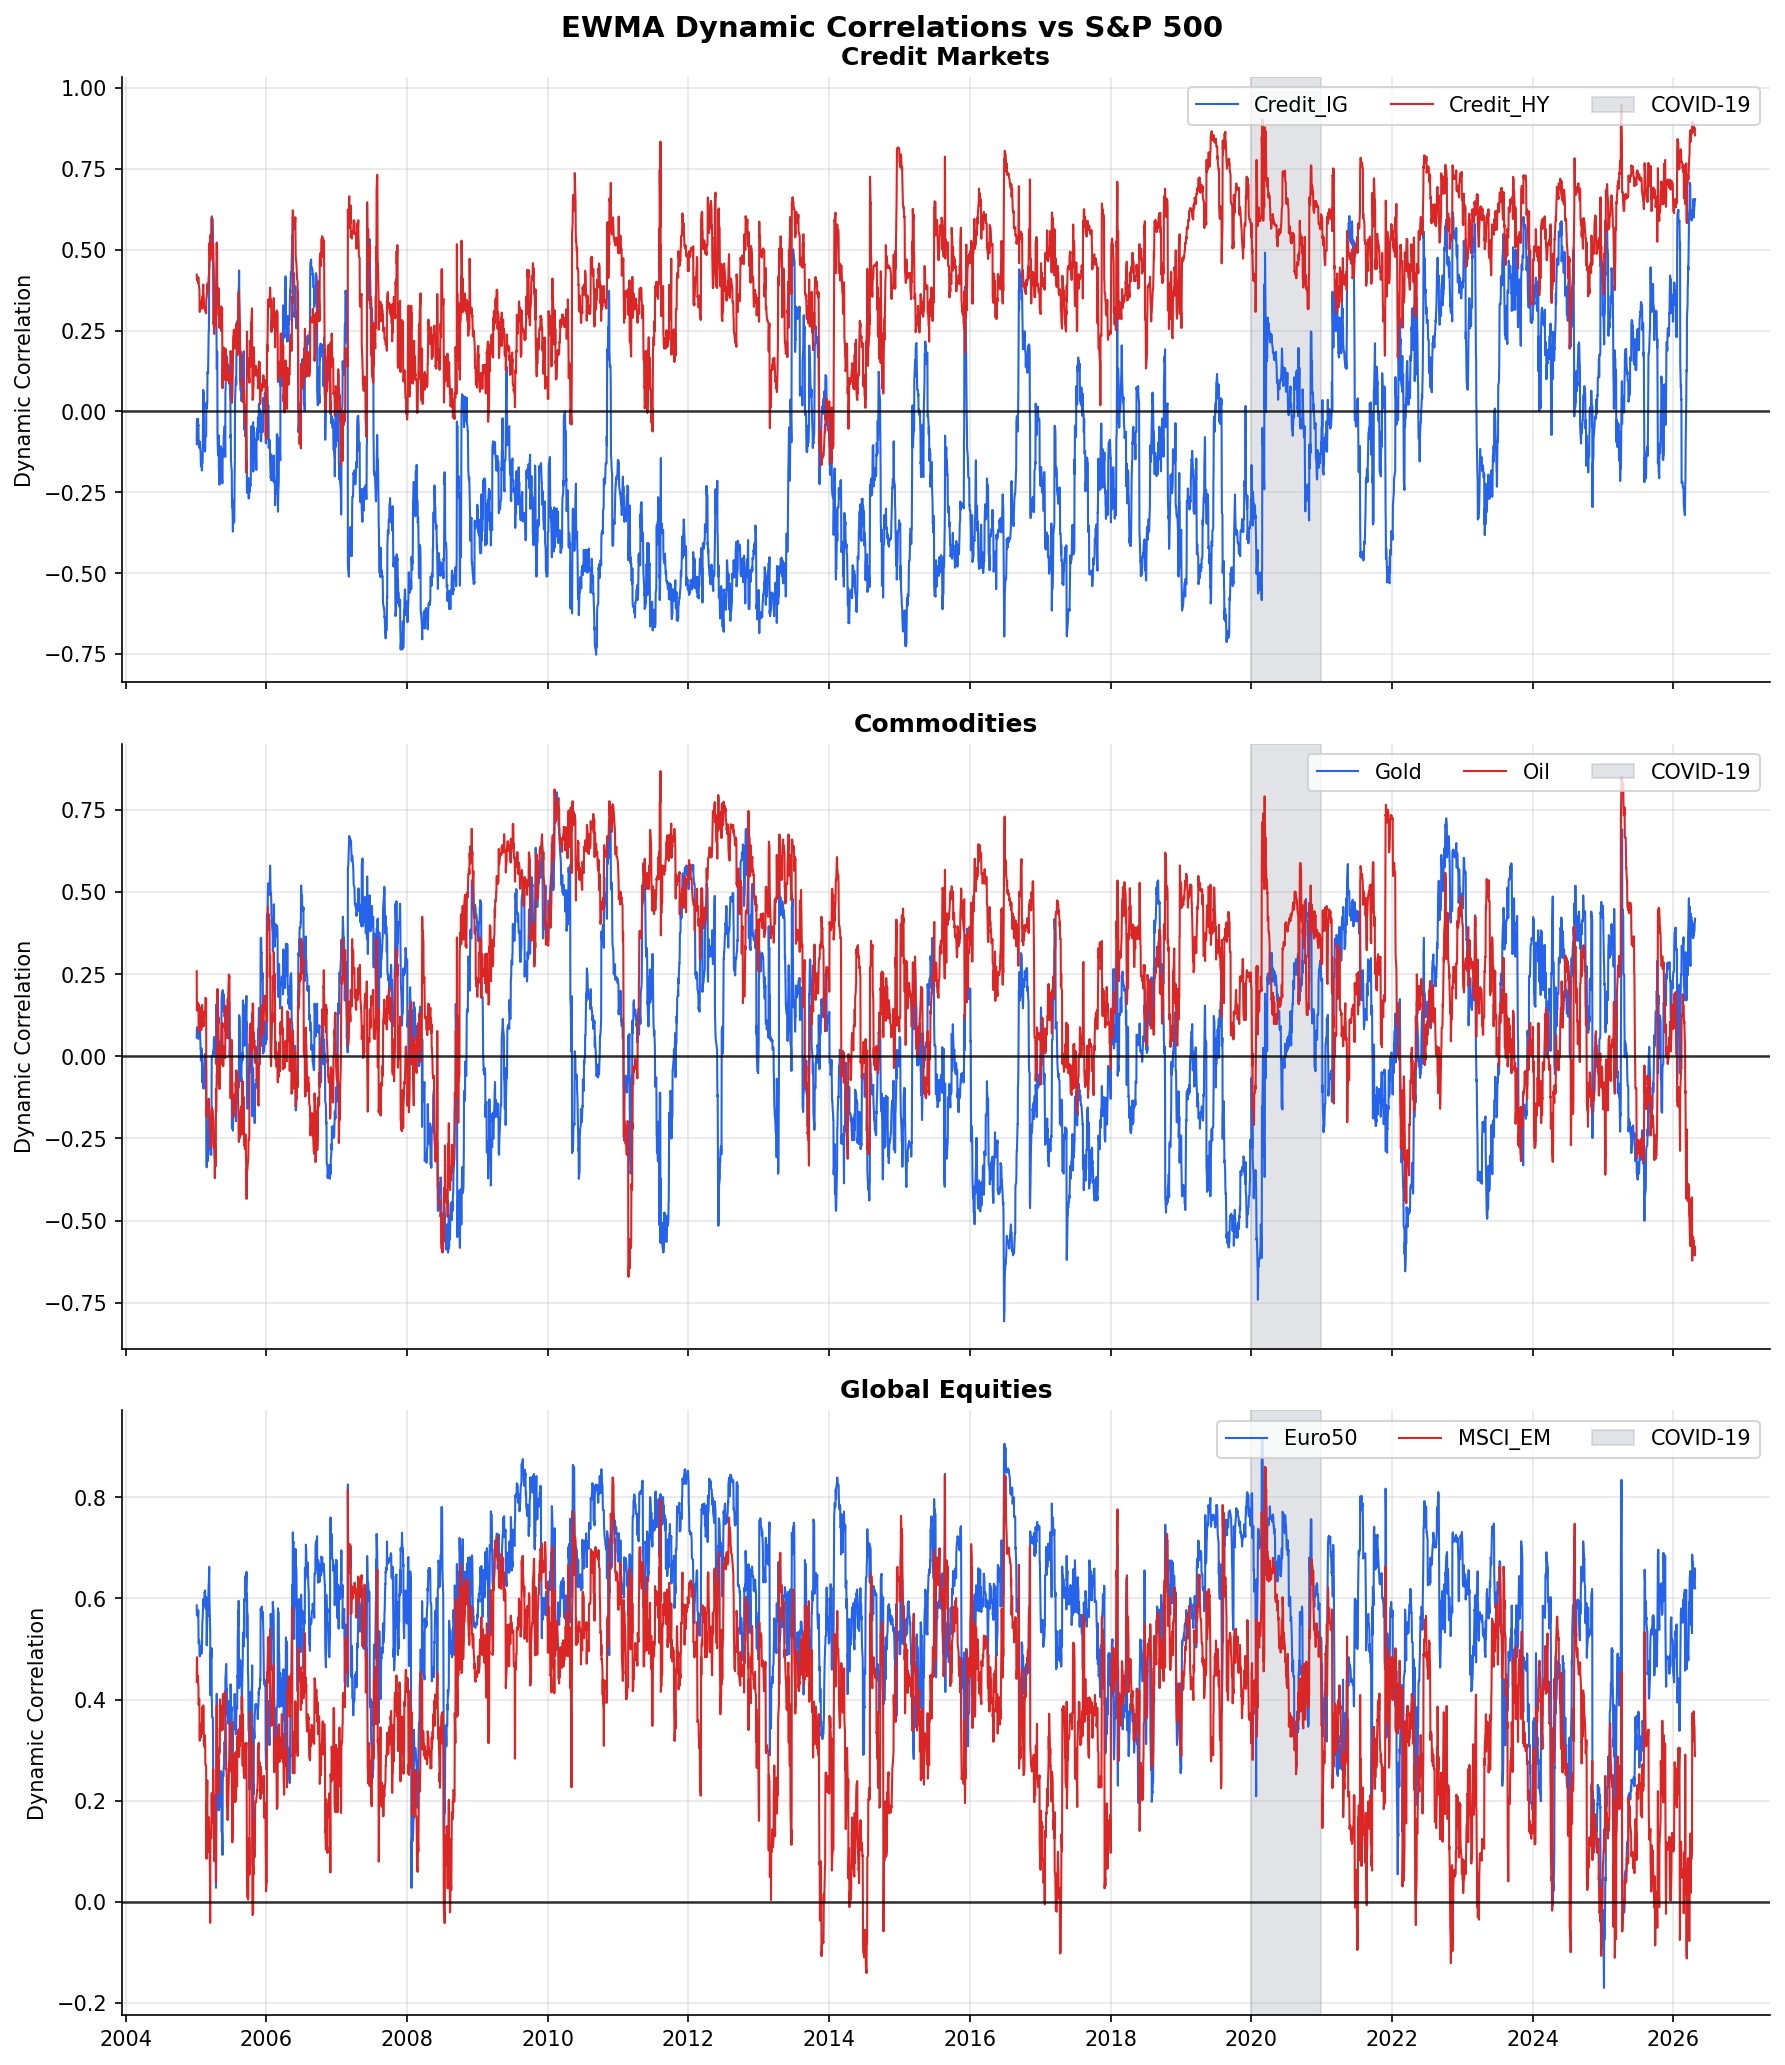

In [26]:
def compute_dynamic_correlation(ret1, ret2, lam=0.94):
    ret1 = ret1.fillna(0)
    ret2 = ret2.fillna(0)
    r1, r2 = ret1 - ret1.mean(), ret2 - ret2.mean()

    var1  = np.zeros(len(r1))
    var2  = np.zeros(len(r2))
    cov12 = np.zeros(len(r1))

    var1[0], var2[0], cov12[0] = r1.var(), r2.var(), np.cov(r1, r2)[0, 1]

    for t in range(1, len(r1)):
        var1[t]  = (1 - lam) * r1.iloc[t-1] ** 2         + lam * var1[t-1]
        var2[t]  = (1 - lam) * r2.iloc[t-1] ** 2         + lam * var2[t-1]
        cov12[t] = (1 - lam) * r1.iloc[t-1] * r2.iloc[t-1] + lam * cov12[t-1]

    rho = cov12 / np.sqrt(var1 * var2)
    return pd.Series(rho, index=ret1.index)


assets_to_test = {
    "Credit_IG" : "us_ig",
    "Credit_HY" : "us_hy",
    "Gold"      : "gold",
    "Oil"       : "oil",
    "Euro50"    : "euro50",
    "MSCI_EM"   : "msci_em",
}

dyn_corrs = pd.DataFrame(index=returns_model.index)
for name, ticker in assets_to_test.items():
    dyn_corrs[name] = compute_dynamic_correlation(
        returns_model["sp500"], returns_model[ticker]
    )

test_idx        = pre_covid_model.index.union(post_covid_model.index)
break_test_df   = dyn_corrs.loc[test_idx].copy()
break_test_df["Post_COVID_Dummy"] = np.where(
    break_test_df.index >= pd.Timestamp(POST_START), 1, 0
)

break_results_ewma = []
for name in assets_to_test.keys():
    model   = smf.ols(formula=f"Q('{name}') ~ Post_COVID_Dummy", data=break_test_df)
    results = model.fit(cov_type="HAC", cov_kwds={"maxlags": 22})

    pre_mean = results.params["Intercept"]
    shift    = results.params["Post_COVID_Dummy"]
    p_value  = results.pvalues["Post_COVID_Dummy"]

    break_results_ewma.append({
        "Asset Pair (vs SP500)"  : name,
        "Pre-COVID Avg rho"      : pre_mean,
        "Post-COVID Avg rho"     : pre_mean + shift,
        "Shift (delta rho)"      : shift,
        "Break p-value"          : p_value,
        "Structural Break?"      : ("Yes (1%)" if p_value < 0.01 else
                                    ("Yes (5%)" if p_value < 0.05 else "No")),
    })

break_summary_ewma = pd.DataFrame(break_results_ewma).set_index("Asset Pair (vs SP500)")

display_ewma = break_summary_ewma.copy()
display_ewma["Break p-value"] = display_ewma["Break p-value"].apply(lambda x: f"{x:.4e}")

sep = "-" * 60
print(sep)
print("  Structural Break Tests — EWMA Dynamic Correlations vs S&P 500")
print(f"  HAC SE, maxlags = 22   |   H0: no level shift after {POST_START}")
print(sep)
print(display_ewma.round(4).to_string())

plot_groups = [
    ("Credit Markets",  ["Credit_IG", "Credit_HY"]),
    ("Commodities",     ["Gold",      "Oil"]),
    ("Global Equities", ["Euro50",    "MSCI_EM"]),
]

colors = ["#2563EB", "#DC2626"]

fig, axes = plt.subplots(3, 1, figsize=(12, 14), sharex=True)
fig.suptitle("EWMA Dynamic Correlations vs S&P 500",
             fontsize=14, fontweight="bold", y=0.98)

for i, (group_name, cols) in enumerate(plot_groups):
    ax = axes[i]
    for j, col in enumerate(cols):
        ax.plot(dyn_corrs.index, dyn_corrs[col],
                label=col, color=colors[j], linewidth=1)
    ax.axvspan(pd.Timestamp(COVID_START), pd.Timestamp(COVID_END),
               color="#9CA3AF", alpha=0.3, label="COVID-19")
    ax.axhline(0, color="black", linewidth=1.2, alpha=0.8)
    ax.set_title(group_name, fontsize=12, fontweight="bold")
    ax.set_ylabel("Dynamic Correlation")
    ax.legend(loc="upper right", ncol=3)
    ax.grid(True, alpha=0.3)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout()
plt.savefig(FIG_DIR / "dynamic_correlations_broad_market.png",
            dpi=150, bbox_inches="tight")
plt.show()

The break test table reports the pre- and post-COVID average EWMA correlation, the estimated shift and the HAC p-value for each pair. The three panels show the EWMA correlation series grouped by asset class, with the COVID year shaded in grey.